In [1]:
!pip uninstall -y massi
!pip cache purge

Found existing installation: massi 0.1.0
Uninstalling massi-0.1.0:
  Successfully uninstalled massi-0.1.0
Files removed: 6 (1.2 MB)


In [2]:
!cd ../.. && pip install -v . --group=dev --group=observability --group=analysis

Using pip 25.3 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
Processing /home/jovyan/work
  Running command installing build dependencies
  Using pip 25.3 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/9d/76/f789f7a86709c6b087c5a2f52f911838cad707cc613162401badc665acfe/setuptools-82.0.1-py3-none-any.whl.metadata
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.0 MB ? eta -:--:--
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 13.0 MB/s  0:00:00
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  running egg_info
  writing massi.egg-info/PKG-INFO
  writing dependency_links to massi.egg-info/dependency_links.txt
  writing requirements to massi.egg-info/requires.txt
  writing top-level names to massi.egg-info/top_level.txt
  reading manifest file 'massi.egg-info/SOURCES.txt'
  writing manifest file

# Overview of Experiment results

In [131]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from lxml import etree

import itertools as ittls
import ast 
import pprint
from pathlib import Path
import json
import math

In [215]:
mpl.rc('xtick', labelsize=6)
mpl.rc('ytick', labelsize=6)

In [4]:
experiment_results = pd.read_csv("../runtime/experiment_cross_scenarios_cases.log.csv")

In [5]:
gbif_cases = pd.read_csv("../runtime/full_gbif_cases.csv")

In [6]:
from typing import TypedDict

class MetricSummary(TypedDict):
    mean: float
    median: float
    min: float
    max: float
    std: float

def get_summary(series: pd.Series) -> MetricSummary:
    """Computes standard descriptive statistics for a numeric series."""
    return {
        "mean": float(series.mean()),
        "median": float(series.median()),
        "min": float(series.min()),
        "max": float(series.max()),
        "std": float(series.std())
    }

In [7]:
class MetadataFileStats(TypedDict):
    schema: str
    
    grand_nr_elements: MetricSummary
    grand_nr_unique_elements: MetricSummary
    group_nr_elements: MetricSummary
    group_nr_unique_elements: MetricSummary
    total_nr_unique_elements: int
    
    grand_nr_attributes: MetricSummary
    grand_nr_unique_attributes: MetricSummary
    group_nr_attributes: MetricSummary
    group_nr_unique_attributes: MetricSummary
    total_nr_unique_attributes: int

    grand_nr_text_nodes: MetricSummary
    group_nr_text_nodes: MetricSummary

    grand_element_depth: MetricSummary
    group_element_depth: MetricSummary

    
    grand_element_fanout_degree: MetricSummary
    group_element_fanout_degree: MetricSummary
    
    grand_element_to_attribute_degree: MetricSummary
    group_element_to_attribute_degree: MetricSummary

    grand_text_content_length: MetricSummary
    group_text_content_length: MetricSummary

In [8]:
def is_hidden_file(fn: str) -> bool:
    return any((
        fn.startswith("__"),  # reserved/hidden files, e.g. __MACOSX
        fn.startswith("."),   # hidden files UNIX
    ))

def is_metadata_xml(fn: str) -> bool:
    """Check for xml but be aware of zip artifacts"""
    return fn.endswith(".xml") and not is_hidden_file(fn)

In [9]:
EXPERIMENT_BASE_DIR = "../../_data/gbif_data_archive/"

def grounded_path(suffix: str | Path) -> Path:
    return Path(EXPERIMENT_BASE_DIR) / suffix

In [10]:
from warnings import warn

def parse_or_error(f): 
    def wrapper(*args):
        try:
            return {"value": f(*args), "error": None}
        except Exception as e:
            return {"error": str(e), "value": None}
    return wrapper

@parse_or_error
def parse_xml_file(path: str | Path):
    return {"tree": etree.parse(path), "identifier": path}

@parse_or_error
def parse_xml_string(data: str, idx: str):
    return {"tree": etree.fromstring(data.encode()), "identifier": idx}   

In [11]:
def tree_to_overviews(tree_container) -> list[dict]:
    error = tree_container["error"]
    if error:
        return []
    tree = tree_container["value"]["tree"]
    identifier = tree_container["value"]["identifier"]
    if tree is not None and bool(identifier):
        return [
            {
                "identifier": identifier,
                "tag": node.tag,
                "depth": sum(1 for _ in node.iterancestors()),
                "nr_attributes": len(node.attrib),
                "nr_unique_attributes": len(set(node.attrib.keys())),
                "fanout": len(node),
                "text_length": len(tx["text"]),
                "attr_names": set(node.attrib.keys()),
                "is_text_node": bool(tx["text"]) ,
                "text_content": tx["text"],
            } 
            for node in tree.iter()
            if (tx := dict(text=node.text.strip() if node.text else ""))
        ]
    else:
        return []

In [12]:
def overviews_to_df(overviews: pd.Series) -> pd.DataFrame:
    all_overviews = ittls.chain.from_iterable(overviews)
    return pd.DataFrame.from_records(all_overviews)

In [13]:
def element_overviews_to_file_summary(el_df: pd.Series):    
    file_df = el_df.groupby("identifier").agg(
        nr_elements=('tag', 'count'),
        nr_unique_elements=('tag', 'nunique'),
        total_attributes=('nr_attributes', 'sum'),
        avg_depth=('depth', 'mean'),
        max_depth=('depth', 'max'),
        avg_fanout=('fanout', 'mean'),
        total_text_length=('text_length', 'sum'),
        nr_text_nodes=('text_length', lambda x: (x > 0).sum())
    ).reset_index()
    
    # Add calculated density columns for plotting
    file_df['attr_density'] = file_df['total_attributes'] / file_df['nr_elements']
    
    return file_df

In [14]:
def get_metadata_file_stats(el_df: pd.DataFrame, file_df: pd.DataFrame, schema: str) -> MetadataFileStats:
    # Grand (Pooled) - using Element DF
    total_unique_elements = el_df['tag'].nunique()
    total_unique_attrs = len(set().union(*el_df['attr_names']))
    
    # Group (Distribution of file properties) - using File DF
    return {
        "schema": schema,
        
        # Elements
        "grand_nr_elements": get_summary(file_df['nr_elements']), 
        "grand_nr_unique_elements": get_summary(file_df['nr_unique_elements']),
        "group_nr_elements": get_summary(file_df['nr_elements']), 
        "group_nr_unique_elements": get_summary(file_df['nr_unique_elements']),
        "total_nr_unique_elements": total_unique_elements,
        
        # Attributes
        "grand_nr_attributes": get_summary(file_df['total_attributes']),
        "grand_nr_unique_attributes": get_summary(el_df.groupby("file_path")['nr_unique_attributes'].mean()), 
        "group_nr_attributes": get_summary(el_df.groupby("file_path")['nr_attributes'].mean()),
        "total_nr_unique_attributes": total_unique_attrs,

        # Structure & Content
        "grand_element_depth": get_summary(el_df['depth']),  # Pooled
        "group_element_depth": get_summary(file_df['avg_depth']), # Mean of means
        
        "grand_element_fanout_degree": get_summary(el_df['fanout']),
        "group_element_fanout_degree": get_summary(file_df['avg_fanout']),

        "grand_text_content_length": get_summary(el_df[el_df['text_length'] > 0]['text_length']),
        "group_text_content_length": get_summary(file_df['total_text_length']),
        
        "grand_nr_text_nodes": get_summary(file_df['nr_text_nodes']),
        "group_nr_text_nodes": get_summary(file_df['nr_text_nodes']), # Summarizing the counts
        
        "grand_element_to_attribute_degree": get_summary(el_df['nr_attributes']),
        "group_element_to_attribute_degree": get_summary(file_df['attr_density']),
    }

In [15]:
gbif_cases["paper_download_info_dict"] = gbif_cases["paper_download_info"].apply(ast.literal_eval)
gbif_cases["dwca_zip_info_dict"] = gbif_cases["dwca_zip_info"].apply(ast.literal_eval)

In [16]:
gt_eml_files = gbif_cases["ground_truth_metadata_eml"]
gt_dwc_files = gbif_cases["ground_truth_metadata_dwc"]

In [17]:
gt_eml_element_overviews = overviews_to_df(gt_eml_files.apply(grounded_path).apply(parse_xml_file).apply(tree_to_overviews))
gt_dwc_element_overviews = overviews_to_df(gt_dwc_files.apply(grounded_path).apply(parse_xml_file).apply(tree_to_overviews))

In [18]:
gt_eml_file_overviews = element_overviews_to_file_summary(gt_eml_element_overviews)
gt_dwc_file_overviews = element_overviews_to_file_summary(gt_dwc_element_overviews)

In [19]:
gt_eml_element_overviews.describe(include="all")

,identifier,tag,depth,nr_attributes,nr_unique_attributes,fanout,text_length,attr_names,is_text_node,text_content
count,53666,53666,53666.000000,53666.000000,53666.000000,53666.000000,53666.000000,53666,53666,53666
unique,179,122,NaN,NaN,NaN,NaN,NaN,16,2,15090
top,../../_data/gbif_data_archive/ground_truth/dat...,taxonomicClassification,NaN,NaN,NaN,NaN,NaN,{},True,
freq,6326,5259,NaN,NaN,NaN,NaN,NaN,51180,35886,17780
mean,NaN,NaN,3.823166,0.060858,0.060858,0.996665,34.029479,NaN,NaN,NaN
std,NaN,NaN,1.006971,0.354425,0.354425,9.408301,180.821566,NaN,NaN,NaN
min,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN
25%,NaN,NaN,3.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN
50%,NaN,NaN,4.000000,0.000000,0.000000,0.000000,7.000000,NaN,NaN,NaN
75%,NaN,NaN,5.000000,0.000000,0.000000,2.000000,17.000000,NaN,NaN,NaN


In [20]:
gt_eml_file_overviews.describe(include="all")

,identifier,nr_elements,nr_unique_elements,total_attributes,avg_depth,max_depth,avg_fanout,total_text_length,nr_text_nodes,attr_density
count,179,179.000000,179.000000,179.000000,179.000000,179.000000,179.000000,179.000000,179.000000,179.000000
unique,179,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,../../_data/gbif_data_archive/ground_truth/dat...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,299.810056,69.016760,18.245810,3.582100,5.932961,0.994477,10202.379888,200.480447,0.077726
std,NaN,494.601131,12.220114,13.199248,0.308271,0.431847,0.003963,8481.407882,331.266761,0.034424
min,NaN,31.000000,25.000000,5.000000,2.794872,4.000000,0.967742,531.000000,17.000000,0.003320
25%,NaN,142.000000,63.000000,11.000000,3.397895,6.000000,0.992958,3856.000000,92.000000,0.054033
50%,NaN,206.000000,70.000000,15.000000,3.506711,6.000000,0.995146,8575.000000,135.000000,0.075581
75%,NaN,331.500000,76.500000,22.000000,3.746636,6.000000,0.996983,13711.500000,229.000000,0.095698


In [21]:
gt_dwc_element_overviews.describe(include="all")

,identifier,tag,depth,nr_attributes,nr_unique_attributes,fanout,text_length,attr_names,is_text_node,text_content
count,8826,8826,8826.000000,8826.000000,8826.000000,8826.000000,8826.000000,8826,8826,8826
unique,179,9,NaN,NaN,NaN,NaN,NaN,7,2,25
top,../../_data/gbif_data_archive/ground_truth/dat...,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,NaN,NaN,NaN,"{index, term}",False,
freq,202,7530,NaN,NaN,NaN,NaN,NaN,7472,8545,8545
mean,NaN,NaN,1.959438,1.953886,1.953886,0.979719,0.444596,NaN,NaN,NaN
std,NaN,NaN,0.377779,0.903768,0.903768,6.172877,2.581288,NaN,NaN,NaN
min,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN
25%,NaN,NaN,2.000000,2.000000,2.000000,0.000000,0.000000,NaN,NaN,NaN
50%,NaN,NaN,2.000000,2.000000,2.000000,0.000000,0.000000,NaN,NaN,NaN
75%,NaN,NaN,2.000000,2.000000,2.000000,0.000000,0.000000,NaN,NaN,NaN


In [22]:
gt_dwc_file_overviews.describe(include="all")

,identifier,nr_elements,nr_unique_elements,total_attributes,avg_depth,max_depth,avg_fanout,total_text_length,nr_text_nodes,attr_density
count,179,179.000000,179.000000,179.000000,179.000000,179.0,179.000000,179.000000,179.000000,179.000000
unique,179,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,../../_data/gbif_data_archive/ground_truth/dat...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,49.307263,6.905028,96.340782,1.951754,3.0,0.975877,21.921788,1.569832,1.948139
std,NaN,23.171091,1.003884,46.010393,0.021203,0.0,0.010602,12.404445,0.718445,0.033823
min,NaN,12.000000,6.000000,22.000000,1.833333,3.0,0.916667,8.000000,1.000000,1.833333
25%,NaN,33.500000,6.000000,65.000000,1.940285,3.0,0.970143,14.000000,1.000000,1.931426
50%,NaN,45.000000,6.000000,90.000000,1.955556,3.0,0.977778,14.000000,1.000000,1.948718
75%,NaN,61.000000,8.000000,119.000000,1.967213,3.0,0.983607,23.000000,2.000000,1.956202


## Metadata Structure

In [23]:
experiment_results.describe()

,Unnamed: 0_x,scenario_id,Unnamed: 0_y,data_standard,case_id,duration_seconds,timestamp
count,716.000000,716.000000,716.000000,716.0,716.000000,716.000000,7.160000e+02
mean,6.000000,6.000000,153.513966,2.0,89.000000,198.872153,1.778234e+09
std,4.475262,4.475262,98.947771,0.0,51.708164,265.107053,7.821494e+04
min,0.000000,0.000000,0.000000,2.0,0.000000,12.870421,1.778149e+09
25%,3.000000,3.000000,67.000000,2.0,44.000000,29.787097,1.778160e+09
50%,6.000000,6.000000,151.000000,2.0,89.000000,132.155694,1.778231e+09
75%,9.000000,9.000000,234.000000,2.0,134.000000,311.472420,1.778326e+09
max,12.000000,12.000000,336.000000,2.0,178.000000,4997.299114,1.778335e+09


In [24]:
experiment_results.columns

Index(['Unnamed: 0_x', 'variant', 'schema', 'strategy', 'provider', 'config',
       'scenario_id', 'scenario_tag', 'Unnamed: 0_y', 'title', 'authors',
       'source', 'published', 'open_access', 'peer_review', 'citation_type',
       'countries_of_coverage', 'countries_of_researcher', 'keywords',
       'literature_type', 'websites', 'identifiers', 'id', 'topics', 'added',
       'gbif_download_key', 'gbif_data_id_data', 'dwca_url', 'data_standard',
       'doi_url', 'genre', 'has_repository_copy', 'is_oa', 'journal_name',
       'published_date', 'publisher', 'best_oa_location.endpoint_id',
       'best_oa_location.oa_date', 'best_oa_location.url',
       'best_oa_location.url_for_landing_page', 'best_oa_location.url_for_pdf',
       'paper_download_file_path', 'dwca_download_path', 'dwca_zip_info',
       'paper_download_info', 'working_copy_data_dir',
       'ground_truth_paper_path', 'ground_truth_metadata_dir',
       'ground_truth_metadata_eml', 'ground_truth_metadata_dwc', 'ca

In [25]:
experiment_results["outcome_dict"] = experiment_results["outcome_json"].apply(json.loads)

In [26]:
successful_experiments = experiment_results[experiment_results["success"]]

In [27]:
successful_experiments["outcome_metadata_xml"] = successful_experiments["outcome_dict"].apply(
    lambda d: d['resolutions'][0]['working_copy_xml_blueprint']["content"]
)

In [28]:
successful_experiments_eml = successful_experiments[successful_experiments["schema"] == "eml"]

In [29]:
for i,p in successful_experiments_eml[
    successful_experiments_eml["outcome_metadata_xml"].apply(lambda x: not x.startswith("<?xml"))
].iterrows(): 
    print(f"--- {i} -- {p['scenario_x_case_tag']}\n", p)

In [30]:
successful_experiments_dwc = successful_experiments[successful_experiments["schema"] == "dwc"]

In [31]:
for i,p in successful_experiments_dwc[
    successful_experiments_dwc["outcome_metadata_xml"].apply(lambda x: not x.startswith("<?xml"))
].iterrows(): 
    print(f"--- {i} -- {p['scenario_x_case_tag']}\n", p)

--- 88 -- c_48-x-s_0--full-dwc-data-focus-openai-platform-{'provider': 'openai-platform', 'core_platform': 'openai', 'proxy_platform': 'openai', 'core_llm': 'gpt-5.4-mini', 'embedding_model': 'text-embedding-3-small', 'rag_llm': 'gpt-5.4-mini'}
 Unnamed: 0_x                                                                             0
variant                                                                               full
schema                                                                                 dwc
strategy                                                                        data-focus
provider                                                                   openai-platform
config                                   {'provider': 'openai-platform', 'core_platform...
scenario_id                                                                              0
scenario_tag                             s_0--full-dwc-data-focus-openai-platform-{'pro...
Unnamed: 0_y              

In [32]:
import re 

def cleanup_gap_failures(xml_data:str) -> str:
    return re.sub(r"\{\{GAP_([0-9]+)[^\}]*\}+", r"not-derived-\1", xml_data)

def cleanup_special_characters(xml_data:str) -> str:
    return re.sub("&", "&amp;", xml_data)

In [33]:
successful_experiments_eml["cleaned_outcome_metadata_xml"] = successful_experiments_eml[
    "outcome_metadata_xml"
].apply(cleanup_gap_failures).apply(cleanup_special_characters)

In [34]:
successful_experiments_eml["parse_result"] = successful_experiments_eml.apply(lambda r: parse_xml_string(r["cleaned_outcome_metadata_xml"], r["short_scenario_x_case_tag"]), axis=1)

In [35]:
valid_xml_exp_eml = successful_experiments_eml[successful_experiments_eml["parse_result"].apply(lambda x: x["value"] is not None)]

In [36]:
valid_xml_exp_eml

,Unnamed: 0_x,variant,schema,strategy,provider,config,scenario_id,scenario_tag,Unnamed: 0_y,title,...,scenario_x_case_tag,short_scenario_x_case_tag,success,outcome_json,duration_seconds,timestamp,outcome_dict,outcome_metadata_xml,cleaned_outcome_metadata_xml,parse_result
354,8,full,eml,data-focus,openai-platform,"{'provider': 'openai-platform', 'core_platform...",8,s_8--full-eml-data-focus-openai-platform-{'pro...,0,Coastal grassland vegetation records from São ...,...,c_0-x-s_8--full-eml-data-focus-openai-platform...,c_0-x-s_8,True,"{""messages"": [], ""settings"": {""runtime_config""...",603.152682,1.778230e+09,"{'messages': [], 'settings': {'runtime_config'...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<eml:e...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<eml:e...",{'value': {'tree': [<Element dataset at 0x7f19...
356,12,full,eml,author-focus,openai-platform,"{'provider': 'openai-platform', 'core_platform...",12,s_12--full-eml-author-focus-openai-platform-{'...,0,Coastal grassland vegetation records from São ...,...,c_0-x-s_12--full-eml-author-focus-openai-platf...,c_0-x-s_12,True,"{""messages"": [], ""settings"": {""runtime_config""...",461.745262,1.778231e+09,"{'messages': [], 'settings': {'runtime_config'...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<eml:e...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<eml:e...",{'value': {'tree': [<Element dataset at 0x7f19...
358,8,full,eml,data-focus,openai-platform,"{'provider': 'openai-platform', 'core_platform...",8,s_8--full-eml-data-focus-openai-platform-{'pro...,2,Dataset on bryophyte species distribution acro...,...,c_2-x-s_8--full-eml-data-focus-openai-platform...,c_2-x-s_8,True,"{""messages"": [], ""settings"": {""runtime_config""...",263.818096,1.778232e+09,"{'messages': [], 'settings': {'runtime_config'...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<eml:e...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<eml:e...",{'value': {'tree': [<Element dataset at 0x7f19...
359,8,full,eml,data-focus,openai-platform,"{'provider': 'openai-platform', 'core_platform...",8,s_8--full-eml-data-focus-openai-platform-{'pro...,3,Insights from the Dalberto Teixeira Pombo (DTP...,...,c_3-x-s_8--full-eml-data-focus-openai-platform...,c_3-x-s_8,True,"{""messages"": [], ""settings"": {""runtime_config""...",686.442346,1.778232e+09,"{'messages': [], 'settings': {'runtime_config'...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<eml:e...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<eml:e...",{'value': {'tree': [<Element dataset at 0x7f19...
360,8,full,eml,data-focus,openai-platform,"{'provider': 'openai-platform', 'core_platform...",8,s_8--full-eml-data-focus-openai-platform-{'pro...,4,Sample event data on ground beetles (Coleopter...,...,c_4-x-s_8--full-eml-data-focus-openai-platform...,c_4-x-s_8,True,"{""messages"": [], ""settings"": {""runtime_config""...",544.695647,1.778233e+09,"{'messages': [], 'settings': {'runtime_config'...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<eml:e...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<eml:e...",{'value': {'tree': [<Element dataset at 0x7f19...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
710,12,full,eml,author-focus,openai-platform,"{'provider': 'openai-platform', 'core_platform...",12,s_12--full-eml-author-focus-openai-platform-{'...,323,Diversity and abundance of soil macroinvertebr...,...,c_174-x-s_12--full-eml-author-focus-openai-pla...,c_174-x-s_12,True,"{""messages"": [], ""settings"": {""runtime_config""...",319.559868,1.778335e+09,"{'messages': [], 'settings': {'runtime_config'...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<eml:e...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<eml:e...",{'value': {'tree': [<Element dataset at 0x7f19...
711,12,full,eml,author-focus,openai-platform,"{'provider': 'openai-platform', 'core_platform...",12,s_12--full-eml-author-focus-openai-platform-{'...,311,Online catalogue of the Coleção de Flebotomíne...,...,c_167-x-s_12--full-eml-author-focus-open

In [37]:
for i,x in enumerate(successful_experiments_eml["cleaned_outcome_metadata_xml"].head()):
    print(f"---- {i}\n", x, "-----")

---- 0
 <?xml version="1.0" encoding="UTF-8"?>
<eml:eml packageId="not-derived-000" system="knb" xmlns:eml="https://eml.ecoinformatics.org/eml-2.2.0" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xml:lang="en">
  <dataset>
    <title>not-derived-001</title>

    <creator>
      <individualName>
        <surName>Calado</surName>
      </individualName>
      <userId directory="https://orcid.org">Calado, H.R.</userId>
    </creator>

    <methods>
      <methodStep>
        <description>
          <para>WGS84</para>
        </description>
        <instrumentation>not-derived-005</instrumentation>
      </methodStep>
      <qualityControl>
        <description>
          <para>not-derived-006</para>
        </description>
      </qualityControl>
    </methods>

    <project>
      <title>Renato_PhD</title>
      <personnel>
        <individualName>
          <surName>Calado</surName>
        </individualName>
        <role>Principal Investigator</role>
      </personnel>
      <pe

In [38]:
successful_experiments_dwc["cleaned_outcome_metadata_xml"] = successful_experiments_dwc[
    "outcome_metadata_xml"
].apply(cleanup_gap_failures).apply(cleanup_special_characters)

In [39]:
successful_experiments_dwc["parse_result"] = successful_experiments_dwc.apply(lambda r: parse_xml_string(r["cleaned_outcome_metadata_xml"], r["short_scenario_x_case_tag"]), axis=1)

In [40]:
valid_xml_exp_dwc = successful_experiments_dwc[successful_experiments_dwc["parse_result"].apply(lambda x: x["value"] is not None)]

In [41]:
valid_xml_exp_dwc

,Unnamed: 0_x,variant,schema,strategy,provider,config,scenario_id,scenario_tag,Unnamed: 0_y,title,...,scenario_x_case_tag,short_scenario_x_case_tag,success,outcome_json,duration_seconds,timestamp,outcome_dict,outcome_metadata_xml,cleaned_outcome_metadata_xml,parse_result
0,0,full,dwc,data-focus,openai-platform,"{'provider': 'openai-platform', 'core_platform...",0,s_0--full-dwc-data-focus-openai-platform-{'pro...,0,Coastal grassland vegetation records from São ...,...,c_0-x-s_0--full-dwc-data-focus-openai-platform...,c_0-x-s_0,True,"{""messages"": [], ""settings"": {""runtime_config""...",30.393199,1.778149e+09,"{'messages': [], 'settings': {'runtime_config'...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<archi...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<archi...",{'value': {'tree': [<Element {http://rs.tdwg.o...
1,0,full,dwc,data-focus,openai-platform,"{'provider': 'openai-platform', 'core_platform...",0,s_0--full-dwc-data-focus-openai-platform-{'pro...,1,Georeferenced checklist and occurrence dataset...,...,c_1-x-s_0--full-dwc-data-focus-openai-platform...,c_1-x-s_0,True,"{""messages"": [], ""settings"": {""runtime_config""...",25.121959,1.778149e+09,"{'messages': [], 'settings': {'runtime_config'...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<archi...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<archi...",{'value': {'tree': [<Element {http://rs.tdwg.o...
2,0,full,dwc,data-focus,openai-platform,"{'provider': 'openai-platform', 'core_platform...",0,s_0--full-dwc-data-focus-openai-platform-{'pro...,2,Dataset on bryophyte species distribution acro...,...,c_2-x-s_0--full-dwc-data-focus-openai-platform...,c_2-x-s_0,True,"{""messages"": [], ""settings"": {""runtime_config""...",54.785212,1.778149e+09,"{'messages': [], 'settings': {'runtime_config'...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<archi...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<archi...",{'value': {'tree': [<Element {http://rs.tdwg.o...
3,0,full,dwc,data-focus,openai-platform,"{'provider': 'openai-platform', 'core_platform...",0,s_0--full-dwc-data-focus-openai-platform-{'pro...,3,Insights from the Dalberto Teixeira Pombo (DTP...,...,c_3-x-s_0--full-dwc-data-focus-openai-platform...,c_3-x-s_0,True,"{""messages"": [], ""settings"": {""runtime_config""...",29.084138,1.778149e+09,"{'messages': [], 'settings': {'runtime_config'...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<archi...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<archi...",{'value': {'tree': [<Element {http://rs.tdwg.o...
4,0,full,dwc,data-focus,openai-platform,"{'provider': 'openai-platform', 'core_platform...",0,s_0--full-dwc-data-focus-openai-platform-{'pro...,4,Sample event data on ground beetles (Coleopter...,...,c_4-x-s_0--full-dwc-data-focus-openai-platform...,c_4-x-s_0,True,"{""messages"": [], ""settings"": {""runtime_config""...",765.560462,1.778150e+09,"{'messages': [], 'settings': {'runtime_config'...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<archi...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<archi...",{'value': {'tree': [<Element {http://rs.tdwg.o...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
353,4,full,dwc,author-focus,openai-platform,"{'provider': 'openai-platform', 'core_platform...",4,s_4--full-dwc-author-focus-openai-platform-{'p...,336,Plant occurrences on the Rybachy and the Sredn...,...,c_178-x-s_4--full-dwc-author-focus-openai-plat...,c_178-x-s_4,True,"{""messages"": [], ""settings"": {""runtime_config""...",19.413431,1.778169e+09,"{'messages': [], 'settings': {'runtime_config'...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<archi...","<?xml version=""1.0"" encoding=""UTF-8""?>\n<archi...",{'value': {'tree': [<Element {http://rs.tdwg.o...
442,4,full,dwc,author-focus,openai-platform,"{'provider': 'openai-platform', 'core_platform...",4,s_4--full-dwc-author-focus-openai-platform-{'p...,309,Sand fly (Diptera: Psychodidae: Phlebotominae)...,...,c_165-x-s_4--full-dwc-author-focus-openai-plat...,c_165-x-s_4,Tru

> From success, to parsing, to XML validity

In [43]:
(successful_experiments_dwc.shape[0], valid_xml_exp_dwc.shape[0])

(354, 348)

In [45]:
(successful_experiments_eml.shape[0], valid_xml_exp_eml.shape[0])

(313, 298)

### Schema Validity

In [46]:
import massi.agents.tools as matls

In [47]:
dwc_validator = matls.get_xmlschema_validator('http://rs.tdwg.org/dwc/text/tdwg_dwc_text.xsd')

/opt/conda/lib/python3.13/site-packages/xmlschema/loaders.py:312: XMLSchemaImportWarning: Import of namespace 'http://purl.org/dc/terms/' from ['http://dublincore.org/schemas/xmls/qdc/2008/02/11/dcterms.xsd'] failed: can't access to resource 'http://dublincore.org/schemas/xmls/qdc/2008/02/11/dcterms.xsd': Forbidden.
  return self.schema_class(
/opt/conda/lib/python3.13/site-packages/xmlschema/loaders.py:312: XMLSchemaImportWarning: Import of namespace 'http://purl.org/dc/elements/1.1/' from ['http://dublincore.org/schemas/xmls/qdc/dc.xsd'] failed: can't access to resource 'http://dublincore.org/schemas/xmls/qdc/dc.xsd': Forbidden.
  return self.schema_class(


In [48]:
eml_validator = matls.get_xmlschema_validator('https://eml.ecoinformatics.org/eml-2.2.0/eml.xsd')

#### DwC Validator

In [49]:
valid_xml_exp_dwc["valid_by_xml_schema"] = valid_xml_exp_dwc["cleaned_outcome_metadata_xml"].apply(dwc_validator.validate)

In [50]:
valid_xml_exp_dwc["valid_by_xml_schema.is_okay"] = valid_xml_exp_dwc["valid_by_xml_schema"].apply(lambda x: x[0])

In [51]:
valid_xml_exp_dwc["valid_by_xml_schema.is_okay"].value_counts()

valid_by_xml_schema.is_okay
True     347
False      1
Name: count, dtype: int64

In [52]:
valid_xml_exp_dwc["valid_by_xml_schema.errors"] = valid_xml_exp_dwc["valid_by_xml_schema"].apply(lambda x: x[1])

In [53]:
for es in valid_xml_exp_dwc[valid_xml_exp_dwc["valid_by_xml_schema.is_okay"] == False]["valid_by_xml_schema.errors"].head():
    print(es)

[XMLSchemaDecodeError(reason="attribute index='not-derived-003': invalid literal for int() with base 10: 'not-derived-003'"), XMLSchemaChildrenValidationError(reason="The content of element '{http://rs.tdwg.org/dwc/text/}extension' is not complete. Tag 'arch:field' expected.")]


#### EML Validator

In [54]:
valid_xml_exp_eml["valid_by_xml_schema"] = valid_xml_exp_eml["cleaned_outcome_metadata_xml"].apply(eml_validator.validate)

In [55]:
valid_xml_exp_eml["valid_by_xml_schema.is_okay"] = valid_xml_exp_eml["valid_by_xml_schema"].apply(lambda x: x[0])

In [56]:
valid_xml_exp_eml["valid_by_xml_schema.is_okay"].value_counts()

valid_by_xml_schema.is_okay
False    298
Name: count, dtype: int64

In [57]:
valid_xml_exp_eml["valid_by_xml_schema.errors"] = valid_xml_exp_eml["valid_by_xml_schema"].apply(lambda x: x[1])

In [58]:
for es in valid_xml_exp_eml["valid_by_xml_schema.errors"].head():
    print(es)

[XMLSchemaValidationError(reason="value must be one of ['annually', 'asNeeded', 'biannually', 'continually', 'daily', 'irregular', 'monthly', 'notPlanned', 'weekly', 'unknown', 'unkown', 'otherMaintenancePeriod']"), XMLSchemaChildrenValidationError(reason="Unexpected child with tag 'methods' at position 3. Tag 'contact' expected."), XMLSchemaChildrenValidationError(reason="The content of element 'metadata' is not complete.")]
[XMLSchemaValidationError(reason="value must be one of ['annually', 'asNeeded', 'biannually', 'continually', 'daily', 'irregular', 'monthly', 'notPlanned', 'weekly', 'unknown', 'unkown', 'otherMaintenancePeriod']"), XMLSchemaChildrenValidationError(reason="Unexpected child with tag 'methods' at position 4. Tag 'contact' expected."), XMLSchemaChildrenValidationError(reason="The content of element 'metadata' is not complete.")]
[XMLSchemaChildrenValidationError(reason="Unexpected child with tag 'methods' at position 3. Tag 'contact' expected.")]
[XMLSchemaValidation

#### Error Overview

- Error counts
- Most frequent errors

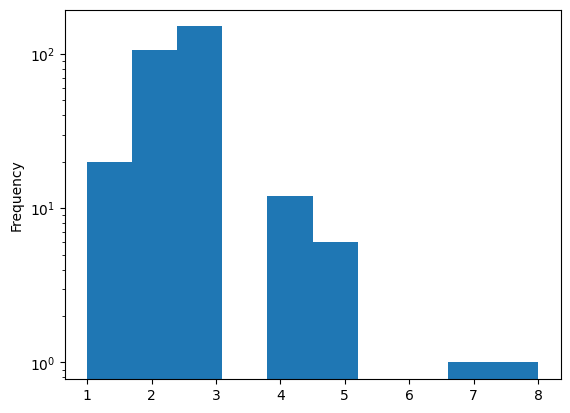

In [59]:
ax = valid_xml_exp_eml["valid_by_xml_schema.errors"].apply(len).plot.hist(log=True)

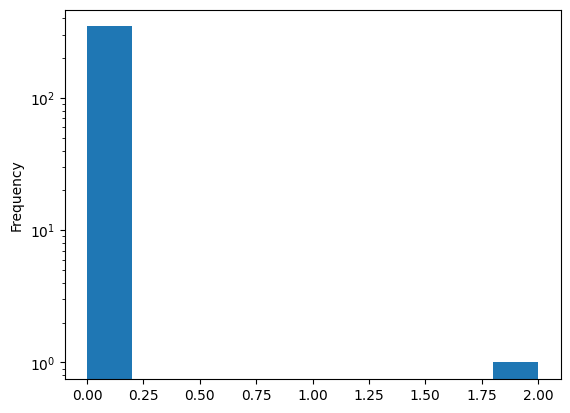

In [60]:
ax = valid_xml_exp_dwc["valid_by_xml_schema.errors"].apply(len).plot.hist(log=True)

In [200]:
successful_experiments_eml_xml_overviews = overviews_to_df(successful_experiments_eml["parse_result"].apply(tree_to_overviews))
successful_experiments_eml_xml_summaries = element_overviews_to_file_summary(successful_experiments_eml_xml_overviews)
successful_experiments_eml_xml_summaries.describe()

,nr_elements,nr_unique_elements,total_attributes,avg_depth,max_depth,avg_fanout,total_text_length,nr_text_nodes,attr_density
count,298.000000,298.000000,298.000000,298.000000,298.000000,298.000000,298.000000,298.000000,298.000000
mean,41.285235,28.231544,7.711409,3.333561,5.100671,0.974736,959.486577,19.020134,0.188863
std,8.969600,4.515228,1.970473,0.181887,0.312370,0.004918,706.966371,5.078468,0.038199
min,32.000000,23.000000,5.000000,3.121212,5.000000,0.968750,213.000000,14.000000,0.102041
25%,34.000000,24.000000,7.000000,3.205882,5.000000,0.970588,349.750000,15.000000,0.156250
50%,40.000000,28.000000,8.000000,3.291078,5.000000,0.975000,759.000000,17.000000,0.187500
75%,47.000000,31.750000,8.000000,3.489362,5.000000,0.978723,1369.500000,22.000000,0.210526
max,76.000000,43.000000,17.000000,3.862069,7.000000,0.986842,3774.000000,37.000000,0.369565


In [201]:
successful_experiments_dwc_xml_overviews = overviews_to_df(successful_experiments_dwc["parse_result"].apply(tree_to_overviews))
successful_experiments_dwc_xml_summaries = element_overviews_to_file_summary(successful_experiments_dwc_xml_overviews)
successful_experiments_dwc_xml_summaries.describe()

,nr_elements,nr_unique_elements,total_attributes,avg_depth,max_depth,avg_fanout,total_text_length,nr_text_nodes,attr_density
count,348.000000,348.000000,348.000000,348.000000,348.0,348.000000,348.000000,348.000000,348.000000
mean,49.178161,6.885057,93.640805,1.951641,3.0,0.975821,21.396552,1.543103,1.894283
std,22.724826,0.994802,44.819140,0.021316,0.0,0.010658,11.748233,0.688216,0.051315
min,12.000000,6.000000,21.000000,1.833333,3.0,0.916667,8.000000,1.000000,1.627907
25%,33.750000,6.000000,64.750000,1.940731,3.0,0.970365,14.000000,1.000000,1.875000
50%,45.000000,6.000000,87.000000,1.955556,3.0,0.977778,14.000000,1.000000,1.902845
75%,61.000000,8.000000,115.000000,1.967213,3.0,0.983607,23.000000,2.000000,1.927536
max,190.000000,8.000000,375.000000,1.989474,3.0,0.994737,74.000000,4.000000,2.030769


{'whiskers': [<matplotlib.lines.Line2D at 0x7f19c84a60d0>,
 'caps': [<matplotlib.lines.Line2D at 0x7f19c84a6350>,
 'boxes': [<matplotlib.lines.Line2D at 0x7f19c807bd90>,
 'medians': [<matplotlib.lines.Line2D at 0x7f19c84a65d0>,
 'fliers': [<matplotlib.lines.Line2D at 0x7f19c84a6710>,
 'means': []}

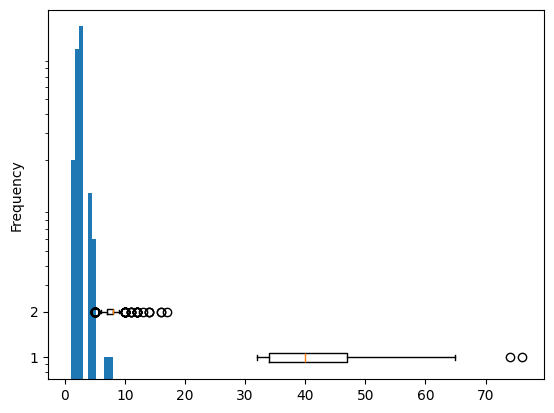

In [63]:
ax = valid_xml_exp_eml["valid_by_xml_schema.errors"].apply(len).plot.hist(log=True)
ax.boxplot([successful_experiments_eml_xml_summaries["nr_elements"], successful_experiments_eml_xml_summaries["total_attributes"]], vert=False)

{'whiskers': [<matplotlib.lines.Line2D at 0x7f197d987b10>,
 'caps': [<matplotlib.lines.Line2D at 0x7f197d987d90>,
 'boxes': [<matplotlib.lines.Line2D at 0x7f19c83bb390>,
 'medians': [<matplotlib.lines.Line2D at 0x7f197d948050>,
 'fliers': [<matplotlib.lines.Line2D at 0x7f197d948190>,
 'means': []}

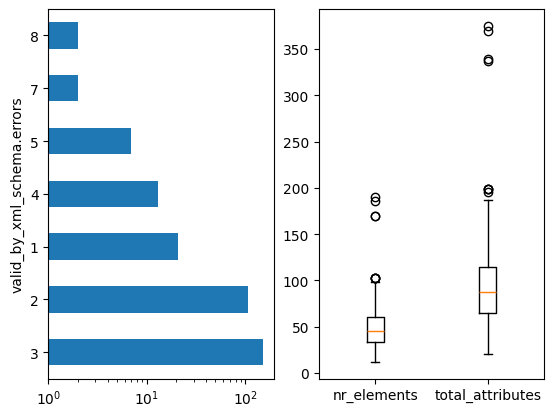

In [64]:
fig, (ax1, ax2) = plt.subplots(1,2)

valid_xml_exp_eml["valid_by_xml_schema.errors"].apply(len).value_counts().plot.barh(log=True, ax=ax1)
ax2.boxplot([successful_experiments_dwc_xml_summaries["nr_elements"], successful_experiments_dwc_xml_summaries["total_attributes"]], tick_labels=["nr_elements", "total_attributes"], vert=True)

In [176]:
# Reusable subplot builder
def column_subplots(fig, subplot_source, data):
    for i, (l, lps, vsx, props, opts) in enumerate(data):
        ax = fig.add_subplot(subplot_source[i])
        ax.tick_params(axis="x", bottom=True, top=False)
        if (xscale := opts.get("xscale", "")):
            ax.set_xscale(xscale)
        if opts.get("boxplots", False):
            ax.boxplot(
                [vs for t, vs in vsx],
                tick_labels=[t for t, vs in vsx],
                flierprops=dict(markersize=2),
                zorder=10,
                **props
            )
            ax.set_xlabel(xl, fontsize=4) if (xl:=opts.get("xlabel", "")) else ...
            ax.set_ylabel(yl, fontsize=4) if (yl:=opts.get("ylabel", "")) else ...
        else:
            for t, vs in vsx:
                ax.hist(vs, **props, label=t, zorder=10)
                ax.set_xlabel(t, fontsize=4) if t else ...
        if (vlines := opts.get("vlines", [])):
            tway = ax.twiny()
            tway.set_xlim(ax.get_xlim())
            if (xscale := opts.get("xscale", "")):
                tway.set_xscale(xscale)
            for vl, vl_props in vlines:
                ax.axvline(
                    vl,
                    zorder=0,
                    **vl_props,
                )
            tway.set_xticks([vl for vl, _ in vlines])
            tway.set_xticklabels([vlp["label"] for _, vlp in vlines], fontsize=4, color="gray", rotation=90, fontstyle="italic")
            tway.tick_params(axis="x", color="gray", pad=1, length=1.75, labelfontfamily="serif")
            tway.minorticks_off()
        if (hists := opts.get("hists", [])):
            twax = ax.twinx()
            twax.set_xlim(ax.get_xlim())
            if (xscale := opts.get("xscale", "")):
                twax.set_xscale(xscale)
            for ht, ht_props in hists:
                twax.hist(
                    ht,
                    zorder=0,
                    **ht_props,
                )
            twax.set_yticks([],[])
        if opts.get("legend", False):
            ax.legend(fontsize=4)
        ax.set_title(l, size=8, **lps)

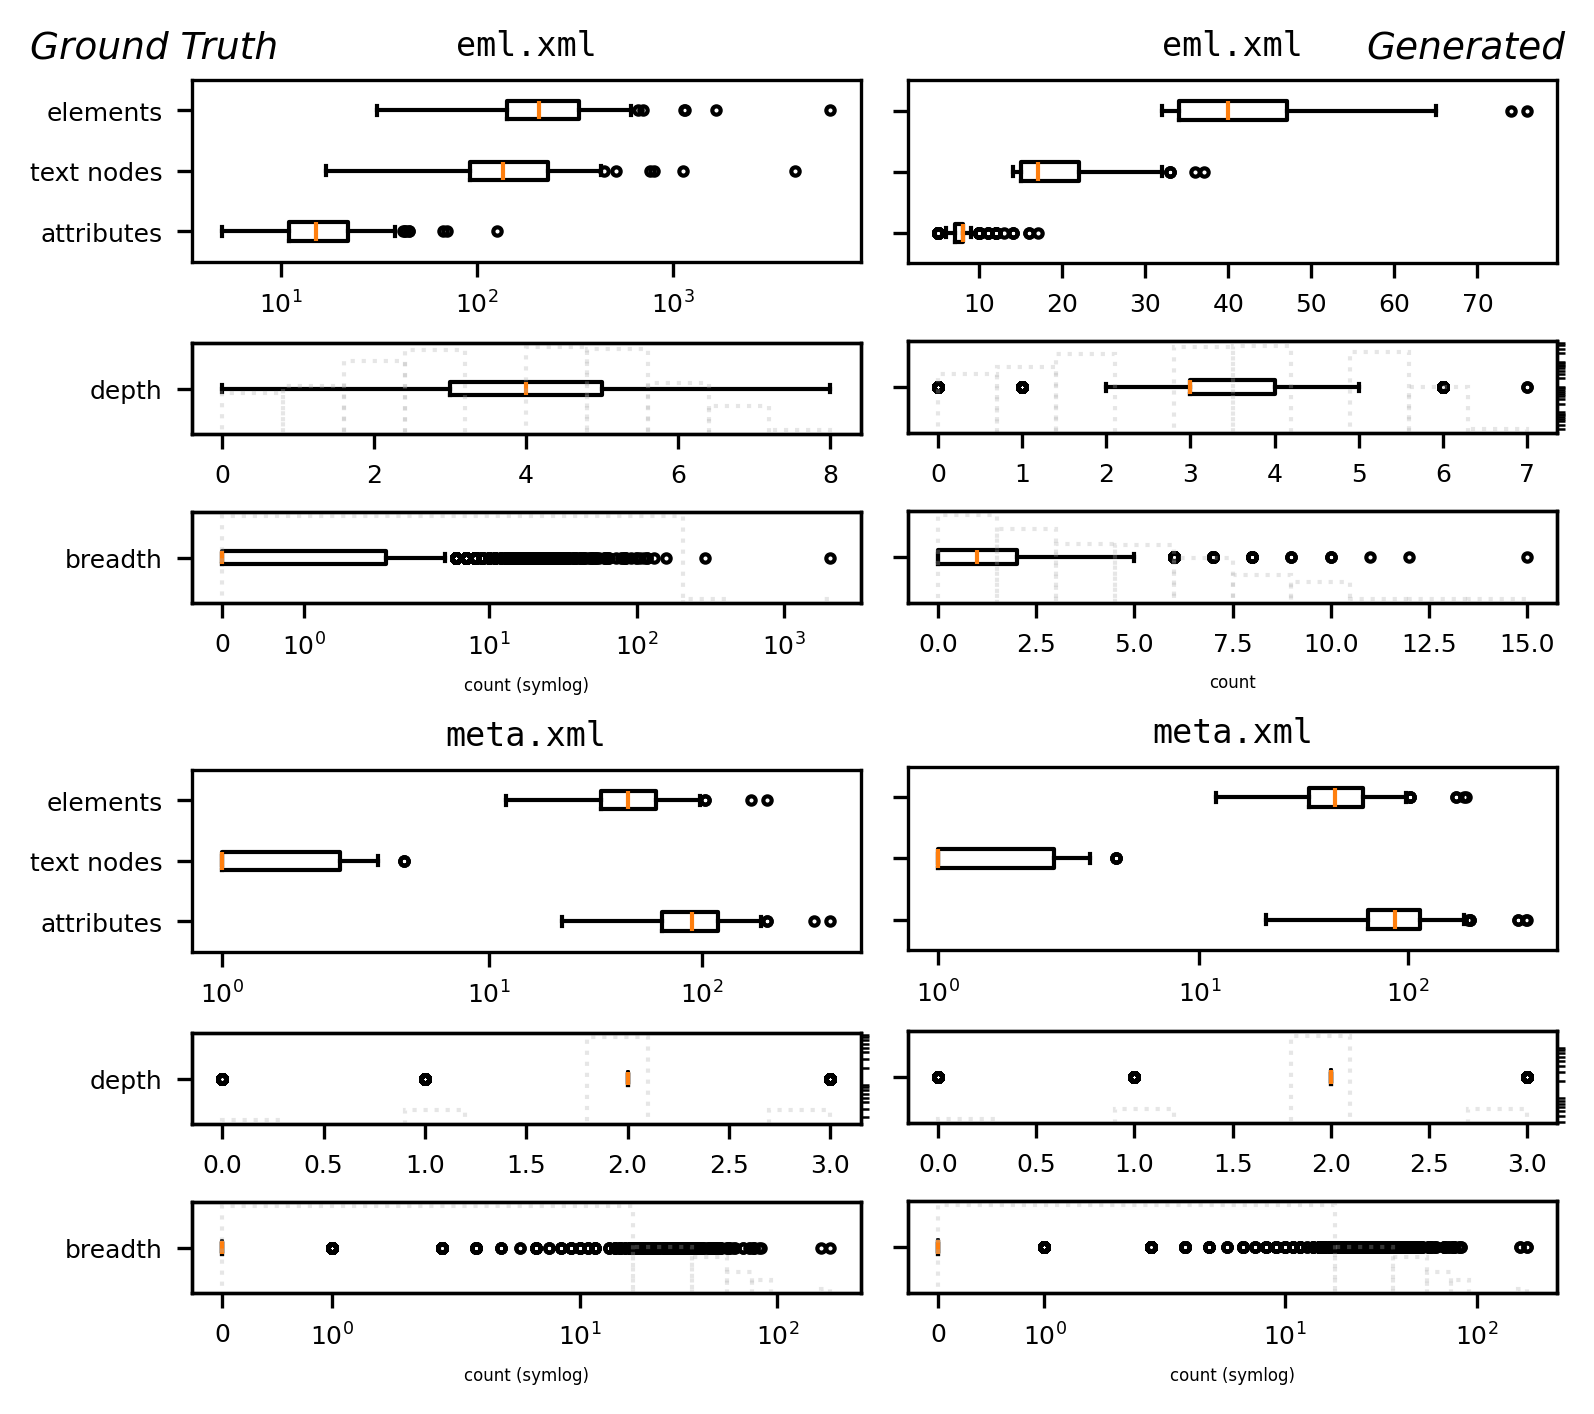

In [219]:
figsize = (5.2, 4.6)
dpi = 300
layout = """
    AAAAABBBB
"""

fig, axd = plt.subplot_mosaic(
    layout,
    figsize=figsize,
    dpi=dpi,
    constrained_layout=True
)

# Subplot 1: Ground Truth EML & DwC-Text Metadata Info
axd['A'].set_title("Ground Truth", loc="left", fontsize=9, fontstyle="italic")
gs_a = axd['A'].get_subplotspec().subgridspec(6, 1, height_ratios=[2,1,1,2,1,1])
column_subplots(
    fig,
    gs_a,
    [
        (
            "eml.xml", dict(fontfamily="monospace"),
            [
                ("attributes", gt_eml_file_overviews["total_attributes"]),
                ("text nodes", gt_eml_file_overviews["nr_text_nodes"]),
                ("elements", gt_eml_file_overviews["nr_elements"]),
            ],
            dict(vert=False),
            dict(
                boxplots=True, 
                xscale="symlog", 
                # vlines=[
                #     (
                #         gt_eml_element_overviews["tag"].unique().shape[0],
                #         dict(ls="-.", color="#aeaeae4d", linewidth=1, label="|e|")
                #     ),
                #     (
                #         gt_eml_element_overviews[gt_eml_element_overviews["is_text_node"]]["tag"].unique().shape[0], 
                #         dict(ls="--", color="#aeaeae4d", linewidth=1, label="|t|")                        
                #     ),
                #     (
                #         len(set(list(ittls.chain.from_iterable(gt_eml_element_overviews["attr_names"].tolist())))),
                #         dict(ls=":", color="#aeaeae4d", linewidth=1, label="|a|")      
                #     ),
                # ]
            )
        ),
        (
            "", 
            {},
            [("depth", gt_eml_element_overviews["depth"])],
            dict(vert=False),
            dict(boxplots=True, hists=[(gt_eml_element_overviews["depth"], dict(log=True, ls=":", color="#ffffff00", edgecolor="#aeaeae4d", linewidth=1))])
        ),
        (
            "", 
            {},
            [("breadth", gt_eml_element_overviews["fanout"])],
            dict(vert=False),
            dict(
                boxplots=True, 
                xlabel="count (symlog)", 
                xscale="symlog", 
                hists=[(gt_eml_element_overviews["fanout"], dict(log=True, ls=":", color="#ffffff00", edgecolor="#aeaeae4d", linewidth=1))]
            )
        ),
        (
            "meta.xml", dict(fontfamily="monospace"),
            [
                ("attributes", gt_dwc_file_overviews["total_attributes"]),
                ("text nodes", gt_dwc_file_overviews["nr_text_nodes"]),
                ("elements", gt_dwc_file_overviews["nr_elements"]),
            ],
            dict(vert=False),
            dict(
                boxplots=True, 
                xscale="symlog", 
                # vlines=[
                #     (
                #         gt_dwc_element_overviews["tag"].unique().shape[0],
                #         dict(ls="-.", color="#aeaeae4d", linewidth=1, label="|e|")
                #     ),
                #     (
                #         gt_dwc_element_overviews[gt_dwc_element_overviews["is_text_node"]]["tag"].unique().shape[0], 
                #         dict(ls="--", color="#aeaeae4d", linewidth=1, label="|t|")                        
                #     ),
                #     (
                #         len(set(list(ittls.chain.from_iterable(gt_dwc_element_overviews["attr_names"].tolist())))),
                #         dict(ls=":", color="#aeaeae4d", linewidth=1, label="|a|")      
                #     ),
                # ]
            )
        ),
        (
            "", 
            {},
            [("depth", gt_dwc_element_overviews["depth"])],
            dict(vert=False),
            dict(boxplots=True, hists=[(gt_dwc_element_overviews["depth"], dict(log=True, ls=":", color="#ffffff00", edgecolor="#aeaeae4d", linewidth=1))])
        ),
        (
            "", 
            {},
            [("breadth", gt_dwc_element_overviews["fanout"])],
            dict(vert=False),
            dict(
                boxplots=True, 
                xlabel="count (symlog)", 
                xscale="symlog", 
                hists=[(gt_dwc_element_overviews["fanout"], dict(log=True, ls=":", color="#ffffff00", edgecolor="#aeaeae4d", linewidth=1))]
            )
        ),
    ],
)
axd['A'].axis('off')

# Subplot 2: Generated EML & DwC-Text Metadata Info
axd['B'].set_title("Generated", loc="right", fontsize=9, fontstyle="italic")
gs_b = axd['B'].get_subplotspec().subgridspec(6, 1, height_ratios=[2,1,1,2,1,1])
column_subplots(
    fig,
    gs_b,
    [
        (
            "eml.xml", dict(fontfamily="monospace"),
            [
                ("", successful_experiments_eml_xml_summaries["total_attributes"]),
                ("", successful_experiments_eml_xml_summaries["nr_text_nodes"]),
                ("", successful_experiments_eml_xml_summaries["nr_elements"]),
            ],
            dict(vert=False),
            dict(
                boxplots=True, 
                # xscale="symlog", 
                # vlines=[
                #     (
                #         successful_experiments_eml_xml_overviews["tag"].unique().shape[0],
                #         dict(ls="-.", color="#aeaeae4d", linewidth=1, label="|e|")
                #     ),
                #     (
                #         successful_experiments_eml_xml_overviews[successful_experiments_eml_xml_overviews["is_text_node"]]["tag"].unique().shape[0], 
                #         dict(ls="--", color="#aeaeae4d", linewidth=1, label="|t|")                        
                #     ),
                #     (
                #         len(set(list(ittls.chain.from_iterable(successful_experiments_eml_xml_overviews["attr_names"].tolist())))),
                #         dict(ls=":", color="#aeaeae4d", linewidth=1, label="|a|")      
                #     ),
                # ]
            )
        ),
        (
            "", 
            {},
            [("", successful_experiments_eml_xml_overviews["depth"])],
            dict(vert=False),
            dict(boxplots=True, hists=[(successful_experiments_eml_xml_overviews["depth"], dict(log=True, ls=":", color="#ffffff00", edgecolor="#aeaeae4d", linewidth=1))])
        ),
        (
            "", 
            {},
            [("", successful_experiments_eml_xml_overviews["fanout"])],
            dict(vert=False),
            dict(
                boxplots=True, 
                xlabel="count", 
                # xscale="symlog", 
                hists=[(successful_experiments_eml_xml_overviews["fanout"], dict(log=True, ls=":", color="#ffffff00", edgecolor="#aeaeae4d", linewidth=1))]
            )
        ),
        (
            "meta.xml", dict(fontfamily="monospace"),
            [
                ("", successful_experiments_dwc_xml_summaries["total_attributes"]),
                ("", successful_experiments_dwc_xml_summaries["nr_text_nodes"]),
                ("", successful_experiments_dwc_xml_summaries["nr_elements"]),
            ],
            dict(vert=False),
            dict(
                boxplots=True, 
                xscale="symlog", 
                # vlines=[
                #     (
                #         successful_experiments_dwc_xml_overviews["tag"].unique().shape[0],
                #         dict(ls="-.", color="#aeaeae4d", linewidth=1, label="|e|")
                #     ),
                #     (
                #         successful_experiments_dwc_xml_overviews[successful_experiments_dwc_xml_overviews["is_text_node"]]["tag"].unique().shape[0], 
                #         dict(ls="--", color="#aeaeae4d", linewidth=1, label="|t|")                        
                #     ),
                #     (
                #         len(set(list(ittls.chain.from_iterable(successful_experiments_dwc_xml_overviews["attr_names"].tolist())))),
                #         dict(ls=":", color="#aeaeae4d", linewidth=1, label="|a|")      
                #     ),
                # ]
            )
        ),
        (
            "", 
            {},
            [("", successful_experiments_dwc_xml_overviews["depth"])],
            dict(vert=False),
            dict(boxplots=True, hists=[(successful_experiments_dwc_xml_overviews["depth"], dict(log=True, ls=":", color="#ffffff00", edgecolor="#aeaeae4d", linewidth=1))])
        ),
        (
            "", 
            {},
            [("", successful_experiments_dwc_xml_overviews["fanout"])],
            dict(vert=False),
            dict(
                boxplots=True, 
                xlabel="count (symlog)", 
                xscale="symlog", 
                hists=[(successful_experiments_dwc_xml_overviews["fanout"], dict(log=True, ls=":", color="#ffffff00", edgecolor="#aeaeae4d", linewidth=1))]
            )
        ),
    ],
)
axd['B'].axis('off')

# plt.tight_layout()
# plt.savefig("ground-truth-data-eda.png")
# plt.savefig("ground-truth-data-eda.pdf")
plt.show()

### Error Overview

In [65]:
valid_xml_exp_eml["valid_by_xml_schema.error_nr_element_rate_percents"] = valid_xml_exp_eml["valid_by_xml_schema.errors"].apply(len).div(successful_experiments_eml_xml_summaries["nr_elements"].tolist()) * 100

In [66]:
valid_xml_exp_eml["valid_by_xml_schema.error_nr_element_rate_percents"].value_counts()

valid_by_xml_schema.error_nr_element_rate_percents
9.375000    33
8.823529    32
6.250000    23
5.882353    14
5.263158    10
            ..
7.547170     1
7.692308     1
1.818182     1
8.620690     1
8.695652     1
Name: count, Length: 77, dtype: int64

<Axes: xlabel='valid_by_xml_schema.error_nr_element_rate_percents', ylabel='Frequency'>

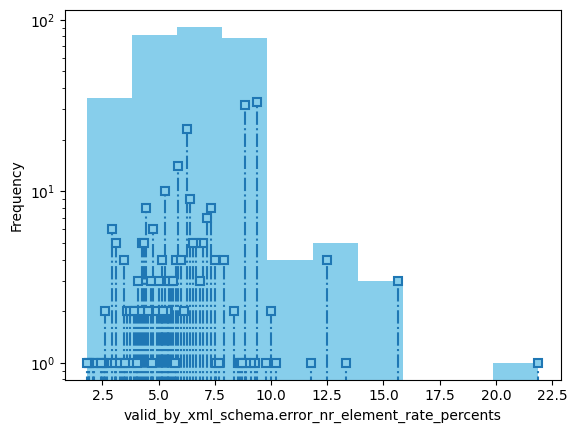

In [67]:
ax = valid_xml_exp_eml["valid_by_xml_schema.error_nr_element_rate_percents"].plot.hist(log=True, color="skyblue")
ax.vlines(ymin=0, ymax=valid_xml_exp_eml["valid_by_xml_schema.error_nr_element_rate_percents"].value_counts().values, x=valid_xml_exp_eml["valid_by_xml_schema.error_nr_element_rate_percents"].value_counts().index, ls="-.")
valid_xml_exp_eml["valid_by_xml_schema.error_nr_element_rate_percents"].value_counts().plot(ax = ax, marker="s", color="#ffffff00", markerfacecolor="skyblue", markeredgecolor="tab:blue", markeredgewidth=1.5)

In [68]:
valid_xml_exp_dwc["valid_by_xml_schema.error_nr_element_rate_percents"] = valid_xml_exp_dwc["valid_by_xml_schema.errors"].apply(len).div(successful_experiments_dwc_xml_summaries["nr_elements"].tolist()) * 100

<Axes: xlabel='valid_by_xml_schema.error_nr_element_rate_percents', ylabel='Frequency'>

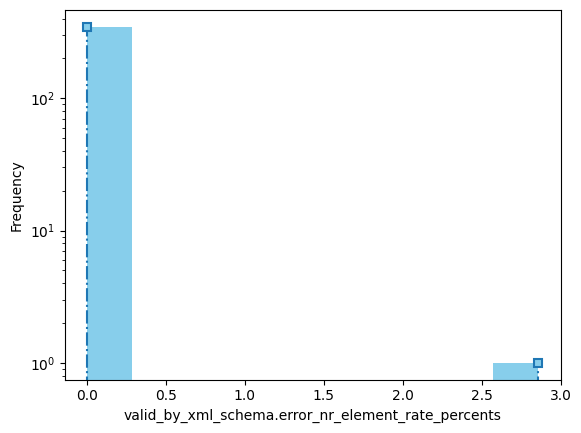

In [69]:
ax = valid_xml_exp_dwc["valid_by_xml_schema.error_nr_element_rate_percents"].plot.hist(log=True, color="skyblue")
ax.vlines(ymin=0, ymax=valid_xml_exp_dwc["valid_by_xml_schema.error_nr_element_rate_percents"].value_counts().values, x=valid_xml_exp_dwc["valid_by_xml_schema.error_nr_element_rate_percents"].value_counts().index, ls="-.")
valid_xml_exp_dwc["valid_by_xml_schema.error_nr_element_rate_percents"].value_counts().plot(ax = ax, marker="s", color="#ffffff00", markerfacecolor="skyblue", markeredgecolor="tab:blue", markeredgewidth=1.5)

##### **EML error insights**

In [70]:
pooled_eml_schema_errors = pd.Series(ittls.chain.from_iterable(valid_xml_exp_eml["valid_by_xml_schema.errors"]))

In [71]:
pooled_eml_schema_error_details = pd.DataFrame.from_records(pooled_eml_schema_errors.apply(lambda e: e.__dict__))

In [72]:
pooled_eml_schema_error_details.head()

,validator,_message,namespaces,source,_sourceline,_path,elem,obj,reason,index,particle,occurs,expected,invalid_tag
0,"[[], [], [], [], [], [], [], [], [], [], [], []]",failed validating 'not-derived-011' with,{'eml': 'https://eml.ecoinformatics.org/eml-2....,XMLResource(root=<Element '{https://eml.ecoinf...,None,None,[],not-derived-011,"value must be one of ['annually', 'asNeeded', ...",NaN,NaN,NaN,NaN,NaN
1,"[[[XsdGroup(name='ResourceGroup', model='seque...",failed validating <Element 'dataset' at 0x7f19...,{'eml': 'https://eml.ecoinformatics.org/eml-2....,XMLResource(root=<Element '{https://eml.ecoinf...,None,None,"[[], [[<Element 'surName' at 0x7f19d51f4a90>],...","[[], [[<Element 'surName' at 0x7f19d51f4a90>],...",Unexpected child with tag 'methods' at positio...,2.0,"(((XsdElement(name='value', occurs=[0, None]))...",0.0,"[((XsdElement(name='salutation', occurs=[0, No...",methods
2,[()],failed validating <Element 'metadata' at 0x7f1...,{'eml': 'https://eml.ecoinformatics.org/eml-2....,XMLResource(root=<Element '{https://eml.ecoinf...,None,None,[],[],The content of element 'metadata' is not compl...,0.0,(),0.0,[()],NaN
3,"[[], [], [], [], [], [], [], [], [], [], [], []]",failed validating 'not-derived-011' with,{'eml': 'https://eml.ecoinformatics.org/eml-2....,XMLResource(root=<Element '{https://eml.ecoinf...,None,None,[],not-derived-011,"value must be one of ['annually', 'asNeeded', ...",NaN,NaN,NaN,NaN,NaN
4,"[[[XsdGroup(name='ResourceGroup', model='seque...",failed validating <Element 'dataset' at 0x7f19...,{'eml': 'https://eml.ecoinformatics.org/eml-2....,XMLResource(root=<Element '{https://eml.ecoinf...,None,None,"[[], [[<Element 'surName' at 0x7f19d51f46d0>],...","[[], [[<Element 'surName' at 0x7f19d51f46d0>],...",Unexpected child with tag 'methods' at positio...,3.0,"(((XsdElement(name='value', occurs=[0, None]))...",0.0,"[((XsdElement(name='salutation', occurs=[0, No...",methods


In [73]:
pooled_eml_schema_error_details["invalid_tag"].value_counts()

invalid_tag
methods                       297
givenName                      20
abstract                       10
para                            8
additionalMetadata              6
sampling                        3
maintenanceDate                 3
provenanceNotes                 3
maintenanceDescription          3
maintenanceUpdateFrequency      2
maintenanceHistory              2
studyAreaDescription            2
organizationName                1
maintenanceUpdateHistory        1
date                            1
dataMaintenance                 1
provenance                      1
dataUpdated                     1
dataPackageMaintenance          1
maintenanceNote                 1
project                         1
maintenanceUpdateDate           1
updateDate                      1
description                     1
dataSetCuration                 1
dataSetURI                      1
Name: count, dtype: int64

In [74]:
pooled_eml_schema_error_details["_path_mask"] = pooled_eml_schema_error_details["_path"].fillna("no-path-given")
pooled_eml_schema_error_details["invalid_tag_mask"] = pooled_eml_schema_error_details["_path"].fillna("no-tag-given")

In [75]:
pooled_eml_schema_error_details[["invalid_tag_mask", "_path_mask", "reason"]].value_counts()

invalid_tag_mask  _path_mask     reason                                                                                                                                                                            
no-tag-given      no-path-given  Unexpected child with tag 'methods' at position 3. Tag 'contact' expected.                                                                                                            274
                                 value must be one of ['annually', 'asNeeded', 'biannually', 'continually', 'daily', 'irregular', 'monthly', 'notPlanned', 'weekly', 'unknown', 'unkown', 'otherMaintenancePeriod']    264
                                 The content of element 'metadata' is not complete.                                                                                                                                    140
                                 Unexpected child with tag 'methods' at position 4. Tag 'contact' expected.                        

In [76]:
pooled_eml_schema_error_details["reason_mask"] = pooled_eml_schema_error_details["reason"].apply(lambda reason: re.sub(r'[0-9]+', '_', reason))

In [77]:
pooled_eml_schema_error_details["reason_mask"].head().tolist()

["value must be one of ['annually', 'asNeeded', 'biannually', 'continually', 'daily', 'irregular', 'monthly', 'notPlanned', 'weekly', 'unknown', 'unkown', 'otherMaintenancePeriod']",
 "Unexpected child with tag 'methods' at position _. Tag 'contact' expected.",
 "The content of element 'metadata' is not complete.",
 "value must be one of ['annually', 'asNeeded', 'biannually', 'continually', 'daily', 'irregular', 'monthly', 'notPlanned', 'weekly', 'unknown', 'unkown', 'otherMaintenancePeriod']",
 "Unexpected child with tag 'methods' at position _. Tag 'contact' expected."]

In [78]:
pooled_eml_schema_error_details[["invalid_tag_mask", "_path_mask", "reason_mask"]].value_counts()

invalid_tag_mask  _path_mask     reason_mask                                                                                                                                                                       
no-tag-given      no-path-given  Unexpected child with tag 'methods' at position _. Tag 'contact' expected.                                                                                                            297
                                 value must be one of ['annually', 'asNeeded', 'biannually', 'continually', 'daily', 'irregular', 'monthly', 'notPlanned', 'weekly', 'unknown', 'unkown', 'otherMaintenancePeriod']    264
                                 The content of element 'metadata' is not complete.                                                                                                                                    140
                                 Unexpected child with tag 'givenName' at position _.                                              

In [79]:
pooled_eml_schema_error_details["reason_mask"].value_counts()

reason_mask
Unexpected child with tag 'methods' at position _. Tag 'contact' expected.                                                                                                            297
value must be one of ['annually', 'asNeeded', 'biannually', 'continually', 'daily', 'irregular', 'monthly', 'notPlanned', 'weekly', 'unknown', 'unkown', 'otherMaintenancePeriod']    264
The content of element 'metadata' is not complete.                                                                                                                                    140
Unexpected child with tag 'givenName' at position _.                                                                                                                                   20
Unexpected child with tag 'abstract' at position _.                                                                                                                                    10
Unexpected child with tag 'para' at position _.           

##### **DwC error insights**

In [80]:
pooled_dwc_schema_errors = pd.Series(ittls.chain.from_iterable(valid_xml_exp_dwc["valid_by_xml_schema.errors"]))

In [81]:
pooled_dwc_schema_error_details = pd.DataFrame.from_records(pooled_dwc_schema_errors.apply(lambda e: e.__dict__))

In [82]:
pooled_dwc_schema_error_details["_path_mask"] = pooled_dwc_schema_error_details["_path"].fillna("no-path-given")
pooled_dwc_schema_error_details["invalid_tag_mask"] = pooled_dwc_schema_error_details["_path"].fillna("no-tag-given")
pooled_dwc_schema_error_details["reason_mask"] = pooled_dwc_schema_error_details["reason"].apply(lambda reason: re.sub(r'[0-9]+', '_', reason))

In [83]:
pooled_dwc_schema_error_details[["invalid_tag_mask", "_path_mask", "reason_mask"]].value_counts()

invalid_tag_mask  _path_mask     reason_mask                                                                                                 
no-tag-given      no-path-given  attribute index='not-derived-_': invalid literal for int() with base _: 'not-derived-_'                         1
                                 The content of element '{http://rs.tdwg.org/dwc/text/}extension' is not complete. Tag 'arch:field' expected.    1
Name: count, dtype: int64

### Field Population Errors

- Number of massi-reported population failures
- Most common fields
- Most common explanations

### Ground-Truth Structural Difference

- Edit distance (APTED)

In [84]:
import apted

In [85]:
from lxml import etree
def xml_to_apted_tree(element):
    """
    Recursively converts an lxml element to an apted.helpers.Tree object.
    Preserves attributes within the node name.
    """
    # 1. Extract the tag name (ignoring namespaces for clarity)
    tag = element.tag
    
    # 2. Handle Attributes: Sort them to ensure deterministic naming
    if element.attrib:
        attr_parts = [f"{{key__{k}{{value__hidden}}" for k, _ in sorted(element.attrib.items())]
        # Label format: TagName:key1__val1:key2__val2
        node_label = f"{tag}:{':'.join(attr_parts)}"
    else:
        node_label = tag

    # 3. Recursively convert all children
    apted_children = [xml_to_apted_tree(child) for child in element]
    
    # 4. Return the apted.helpers.Tree instance
    return apted.helpers.Tree(node_label, *apted_children)


In [220]:
def get_tree_size(tree):
    return 1 + sum(get_tree_size(child) for child in tree.children)

def normalise_distance(raw_distance, tree1, tree2):
    max_dist = get_tree_size(tree1) + get_tree_size(tree2)
    return raw_distance / max_dist if max_dist > 0 else 0

In [86]:
def get_error_breakdown(apted_edit_mapping):
    breakdown = {
        "deletions": [],    # In Tree 1, but not in Tree 2
        "insertions": [],   # In Tree 2, but not in Tree 1
        "renames": [],      # In both, but labels/attributes differ
        "matches": []       # Identical nodes
    }
    
    for node1, node2 in apted_edit_mapping:
        if node1 is None:
            # Node exists only in generated (Tree 2) -> Hallucination
            breakdown["insertions"].append(node2.name)
        elif node2 is None:
            # Node exists only in ground truth (Tree 1) -> Omission
            breakdown["deletions"].append(node1.name)
        else:
            # Both exist; check if the label (tag + attributes) is the same
            if node1.name != node2.name:
                breakdown["renames"].append((node1.name, node2.name))
            else:
                breakdown["matches"].append(node1.name)
                
    return breakdown

##### **EML insights**

In [87]:
valid_xml_exp_eml["ground_truth_bracket_metadata"] = valid_xml_exp_eml["ground_truth_metadata_eml"].apply(grounded_path).apply(etree.parse).apply(lambda t: t.getroot()).apply(xml_to_apted_tree)

In [88]:
valid_xml_exp_eml["outcome_bracket_metadata"] = valid_xml_exp_eml["cleaned_outcome_metadata_xml"].apply(lambda s: s.encode()).apply(etree.fromstring).apply(xml_to_apted_tree)

In [90]:
%%time
valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_distance"] = valid_xml_exp_eml.apply(lambda x: apted.APTED(x["outcome_bracket_metadata"], x["ground_truth_bracket_metadata"]), axis=1).apply(lambda a: dict(edit_distance=a.compute_edit_distance()))

CPU times: user 40.2 s, sys: 0 ns, total: 40.2 s
Wall time: 40.2 s


In [226]:
valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_distance.value"] = valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_distance"].apply(lambda d: d["edit_distance"])
valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_distance.normalised"] = valid_xml_exp_eml.apply(lambda x: normalise_distance(x["ground_truth_to_outcome_apted_edit_distance.value"], x["outcome_bracket_metadata"], x["ground_truth_bracket_metadata"]), axis=1)
valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_distance.similarity_score"] = 1 - valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_distance.normalised"]

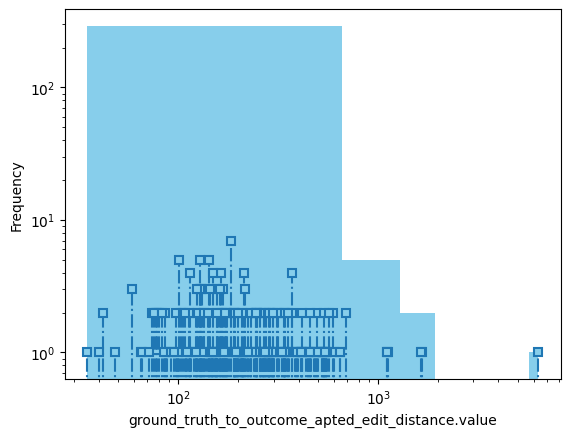

In [159]:
ax = valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_distance.value"].plot.hist(log=True, color="skyblue")
ax.vlines(ymin=0, ymax=valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_distance.value"].value_counts().values, x=valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_distance.value"].value_counts().index, ls="-.")
valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_distance.value"].value_counts().plot(ax = ax, marker="s", color="#ffffff00", markerfacecolor="skyblue", markeredgecolor="tab:blue", markeredgewidth=1.5)
# todo: add ticks for important values
ax.set_xscale("log")

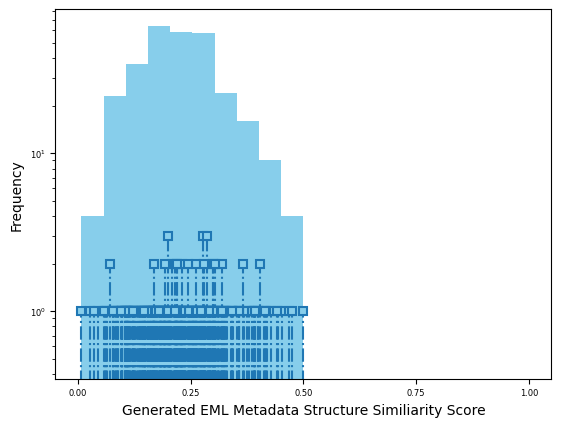

In [250]:
ax = valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_distance.similarity_score"].plot.hist(log=True, color="skyblue")
ax.vlines(ymin=0, ymax=valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_distance.similarity_score"].value_counts().values, x=valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_distance.similarity_score"].value_counts().index, ls="-.")
valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_distance.similarity_score"].value_counts().plot(ax = ax, marker="s", color="#ffffff00", markerfacecolor="skyblue", markeredgecolor="tab:blue", markeredgewidth=1.5)
# todo: add ticks for important values
# ax.set_xscale("symlog")
ax.set_xlabel("Generated EML Metadata Structure Similiarity Score")
ax.set_xlim(-0.05,1.05)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1])

In [94]:
%%time
valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_mapping"] = valid_xml_exp_eml.apply(lambda x: apted.APTED(x["outcome_bracket_metadata"], x["ground_truth_bracket_metadata"]), axis=1).apply(lambda a: a.compute_edit_mapping())

CPU times: user 40.8 s, sys: 27.1 ms, total: 40.8 s
Wall time: 40.8 s


In [95]:
valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_mapping"]

354    [({{https://eml.ecoinformatics.org/eml-2.2.0}e...
356    [({{https://eml.ecoinformatics.org/eml-2.2.0}e...
358    [({{https://eml.ecoinformatics.org/eml-2.2.0}e...
359    [({{https://eml.ecoinformatics.org/eml-2.2.0}e...
360    [({{https://eml.ecoinformatics.org/eml-2.2.0}e...
                             ...                        
710    [({{https://eml.ecoinformatics.org/eml-2.2.0}e...
711    [({{https://eml.ecoinformatics.org/eml-2.2.0}e...
712    [({{https://eml.ecoinformatics.org/eml-2.2.0}e...
713    [({{https://eml.ecoinformatics.org/eml-2.2.0}e...
714    [({{https://eml.ecoinformatics.org/eml-2.2.0}e...
Name: ground_truth_to_outcome_apted_edit_mapping, Length: 298, dtype: object

In [96]:
valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_mapping.breakdown"] = valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_mapping"].apply(get_error_breakdown)

In [97]:
valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_mapping.breakdown.counts"] = valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_mapping.breakdown"].apply(lambda b: {k: len(v) for k,v in b.items()})

In [98]:
valid_xml_exp_eml_ground_truth_edit_mapping_counts = pd.DataFrame.from_records(valid_xml_exp_eml["ground_truth_to_outcome_apted_edit_mapping.breakdown.counts"].tolist())

In [99]:
valid_xml_exp_eml_ground_truth_edit_mapping_counts

,deletions,insertions,renames,matches
0,5,478,3,30
1,5,469,5,37
2,6,340,11,44
3,10,271,11,29
4,5,151,20,20
...,...,...,...,...
293,2,254,17,15
294,6,125,25,17
295,3,65,15,14
296,3,111,14,17


In [100]:
valid_xml_exp_eml_ground_truth_edit_mapping_counts[["insertions"]].describe()

,insertions
count,298.000000
mean,249.030201
std,405.552692
min,4.000000
25%,108.000000
50%,175.000000
75%,286.750000
max,6295.000000


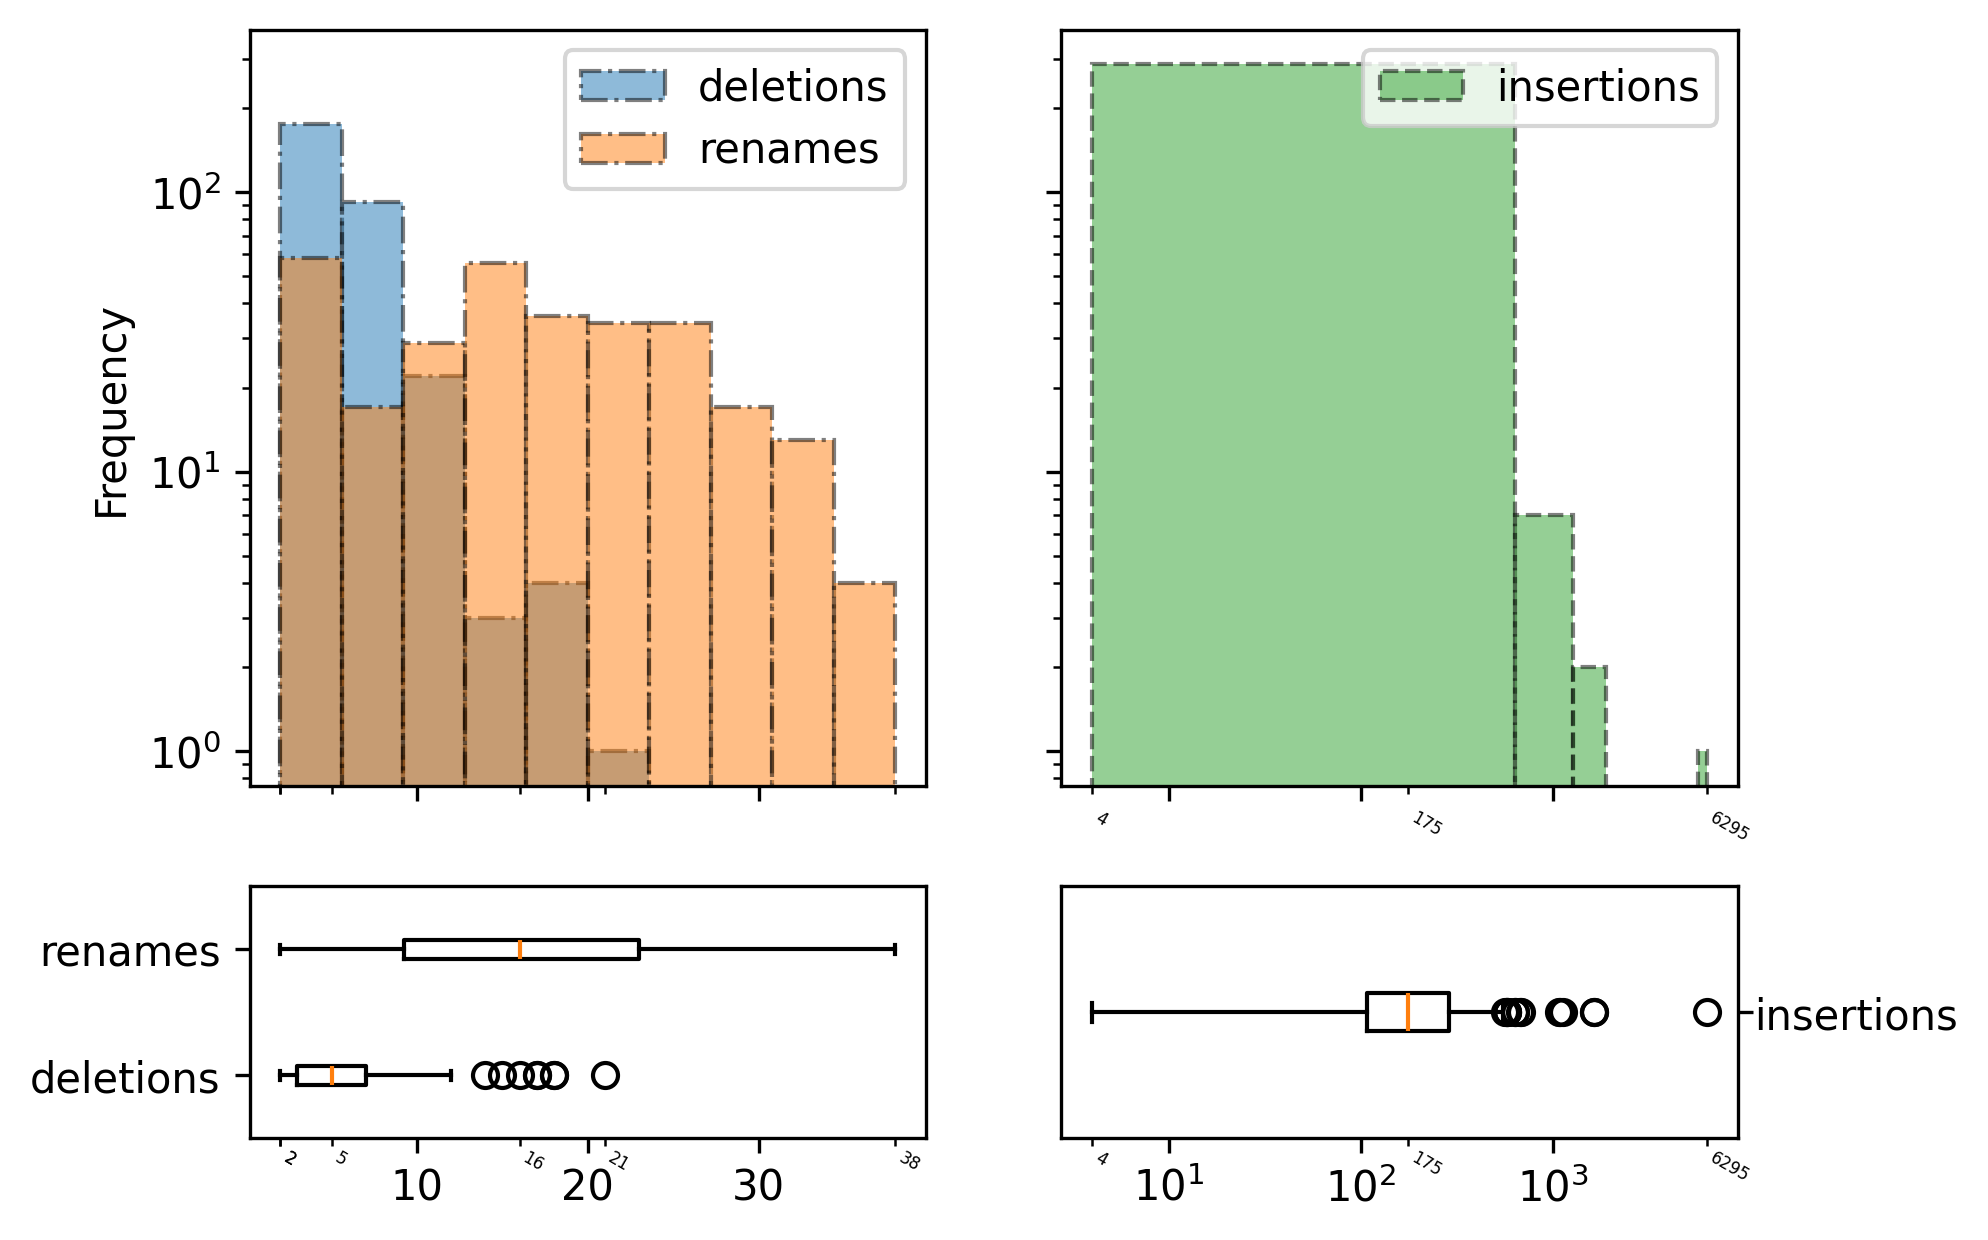

In [153]:
fig, ((ax1, ax2), (bax1, bax2)) = plt.subplots(2,2, height_ratios=((3,1)), dpi=300)
ax1.sharey(ax2)
ax1.sharex(bax1)
ax2.sharex(bax2)
ax2.set_xscale("symlog")
valid_xml_exp_eml_ground_truth_edit_mapping_counts[["deletions", "renames"]].plot.hist(log=True, alpha=0.5, ls="-.", edgecolor="black", ax=ax1)
bax1.boxplot(
    [
        valid_xml_exp_eml_ground_truth_edit_mapping_counts["deletions"],
        valid_xml_exp_eml_ground_truth_edit_mapping_counts["renames"],
    ],
    tick_labels=["deletions", "renames"],
    vert=False
)
bax1.tick_params(axis="y", right=False, labelright=False, left=True, labelleft=True)
bax1.tick_params(axis="x", which="minor", pad=0.5)
bax1.set_xticks(
    [
        valid_xml_exp_eml_ground_truth_edit_mapping_counts["deletions"].min(), math.floor(valid_xml_exp_eml_ground_truth_edit_mapping_counts["deletions"].median()), valid_xml_exp_eml_ground_truth_edit_mapping_counts["deletions"].max(),
        valid_xml_exp_eml_ground_truth_edit_mapping_counts["renames"].min(), math.floor(valid_xml_exp_eml_ground_truth_edit_mapping_counts["renames"].median()), valid_xml_exp_eml_ground_truth_edit_mapping_counts["renames"].max()
    ],
    minor=True
)
ax1.set_xticklabels(
    [], 
    minor=True, 
    fontsize=4,
    horizontalalignment="left",
    rotation=330,
)
bax1.set_xticklabels(
    [
        valid_xml_exp_eml_ground_truth_edit_mapping_counts["deletions"].min(), math.floor(valid_xml_exp_eml_ground_truth_edit_mapping_counts["deletions"].median()), valid_xml_exp_eml_ground_truth_edit_mapping_counts["deletions"].max(),
        valid_xml_exp_eml_ground_truth_edit_mapping_counts["renames"].min(), math.floor(valid_xml_exp_eml_ground_truth_edit_mapping_counts["renames"].median()), valid_xml_exp_eml_ground_truth_edit_mapping_counts["renames"].max()
    ],
    minor=True, 
    fontsize=4,
    horizontalalignment="left",
    rotation=330,
)

valid_xml_exp_eml_ground_truth_edit_mapping_counts[["insertions"]].plot.hist(log=True, alpha=0.5, ls="--", edgecolor="black", ax=ax2, color="tab:green")
bax2.boxplot(
    [
        valid_xml_exp_eml_ground_truth_edit_mapping_counts["insertions"],
    ],
    tick_labels=["insertions"],
    vert=False
)
bax2.tick_params(axis="y", right=True, labelright=True, left=False, labelleft=False, pad=0.5)
bax2.tick_params(axis="x", which="minor", pad=0.5)
bax2.set_xticks(
    [valid_xml_exp_eml_ground_truth_edit_mapping_counts["insertions"].min(), math.floor(valid_xml_exp_eml_ground_truth_edit_mapping_counts["insertions"].median()), valid_xml_exp_eml_ground_truth_edit_mapping_counts["insertions"].max()],
    minor=True
)
ax2.set_xticklabels(
    [], 
    minor=True, 
    fontsize=4,
    horizontalalignment="left",
    rotation=330,
)
bax2.set_xticklabels(
    [valid_xml_exp_eml_ground_truth_edit_mapping_counts["insertions"].min(), math.floor(valid_xml_exp_eml_ground_truth_edit_mapping_counts["insertions"].median()), valid_xml_exp_eml_ground_truth_edit_mapping_counts["insertions"].max()], 
    minor=True, 
    fontsize=4,
    horizontalalignment="left",
    rotation=330,
)
plt.show()

##### **DWC insights**

In [154]:
valid_xml_exp_dwc["ground_truth_bracket_metadata"] = valid_xml_exp_dwc["ground_truth_metadata_dwc"].apply(grounded_path).apply(etree.parse).apply(lambda t: t.getroot()).apply(xml_to_apted_tree)

In [155]:
valid_xml_exp_dwc["outcome_bracket_metadata"] = valid_xml_exp_dwc["cleaned_outcome_metadata_xml"].apply(lambda s: s.encode()).apply(etree.fromstring).apply(xml_to_apted_tree)

In [156]:
%%time
valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_distance"] = valid_xml_exp_dwc.apply(lambda x: apted.APTED(x["outcome_bracket_metadata"], x["ground_truth_bracket_metadata"]), axis=1).apply(lambda a: dict(edit_distance=a.compute_edit_distance()))

CPU times: user 4.17 s, sys: 7.68 ms, total: 4.18 s
Wall time: 4.19 s


In [157]:
valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_distance.value"] = valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_distance"].apply(lambda d: d["edit_distance"])

In [229]:
valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_distance.value"] = valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_distance"].apply(lambda d: d["edit_distance"])
valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_distance.normalised"] = valid_xml_exp_dwc.apply(lambda x: normalise_distance(x["ground_truth_to_outcome_apted_edit_distance.value"], x["outcome_bracket_metadata"], x["ground_truth_bracket_metadata"]), axis=1)
valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_distance.similarity_score"] = 1 - valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_distance.normalised"]

<Axes: xlabel='ground_truth_to_outcome_apted_edit_distance.value', ylabel='Frequency'>

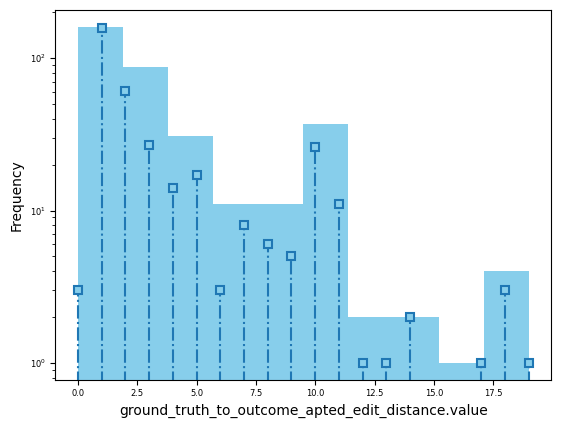

In [230]:
ax = valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_distance.value"].plot.hist(log=True, color="skyblue")
ax.vlines(ymin=0, ymax=valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_distance.value"].value_counts().values, x=valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_distance.value"].value_counts().index, ls="-.")
valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_distance.value"].value_counts().plot(ax = ax, marker="s", color="#ffffff00", markerfacecolor="skyblue", markeredgecolor="tab:blue", markeredgewidth=1.5)
# ax.set_xscale("log")

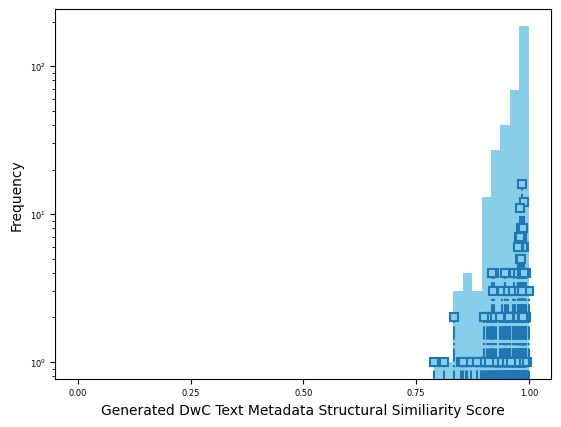

In [251]:
ax = valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_distance.similarity_score"].plot.hist(log=True, color="skyblue")
ax.vlines(ymin=0, ymax=valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_distance.similarity_score"].value_counts().values, x=valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_distance.similarity_score"].value_counts().index, ls="-.")
valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_distance.similarity_score"].value_counts().plot(ax = ax, marker="s", color="#ffffff00", markerfacecolor="skyblue", markeredgecolor="tab:blue", markeredgewidth=1.5)
# ax.set_xscale("symlog")
ax.set_xlim(-0.05,1.05)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
ax.set_xlabel("Generated DwC Text Metadata Structural Similiarity Score")
plt.show()

In [161]:
%%time
valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_mapping"] = valid_xml_exp_dwc.apply(lambda x: apted.APTED(x["outcome_bracket_metadata"], x["ground_truth_bracket_metadata"]), axis=1).apply(lambda a: a.compute_edit_mapping())

CPU times: user 4.52 s, sys: 2.53 ms, total: 4.52 s
Wall time: 4.51 s


In [162]:
valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_mapping"]

0      [({{http://rs.tdwg.org/dwc/text/}archive:{key_...
1      [({{http://rs.tdwg.org/dwc/text/}archive:{key_...
2      [({{http://rs.tdwg.org/dwc/text/}archive:{key_...
3      [({{http://rs.tdwg.org/dwc/text/}archive:{key_...
4      [({{http://rs.tdwg.org/dwc/text/}archive:{key_...
                             ...                        
353    [({{http://rs.tdwg.org/dwc/text/}archive:{key_...
442    [({{http://rs.tdwg.org/dwc/text/}archive:{key_...
443    [({{http://rs.tdwg.org/dwc/text/}archive:{key_...
444    [({{http://rs.tdwg.org/dwc/text/}archive:{key_...
445    [({{http://rs.tdwg.org/dwc/text/}archive:{key_...
Name: ground_truth_to_outcome_apted_edit_mapping, Length: 348, dtype: object

In [163]:
valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_mapping.breakdown"] = valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_mapping"].apply(get_error_breakdown)

In [164]:
valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_mapping.breakdown.counts"] = valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_mapping.breakdown"].apply(lambda b: {k: len(v) for k,v in b.items()})

In [165]:
valid_xml_exp_dwc_ground_truth_edit_mapping_counts = pd.DataFrame.from_records(valid_xml_exp_dwc["ground_truth_to_outcome_apted_edit_mapping.breakdown.counts"].tolist())

In [166]:
valid_xml_exp_dwc_ground_truth_edit_mapping_counts

,deletions,insertions,renames,matches
0,2,1,2,57
1,0,0,1,41
2,5,5,0,59
3,3,2,2,64
4,0,1,3,77
...,...,...,...,...
343,0,0,1,50
344,0,0,1,38
345,0,0,1,38
346,0,0,1,43


In [167]:
valid_xml_exp_dwc_ground_truth_edit_mapping_counts[["insertions"]].describe()

,insertions
count,348.000000
mean,0.925287
std,2.099854
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,16.000000


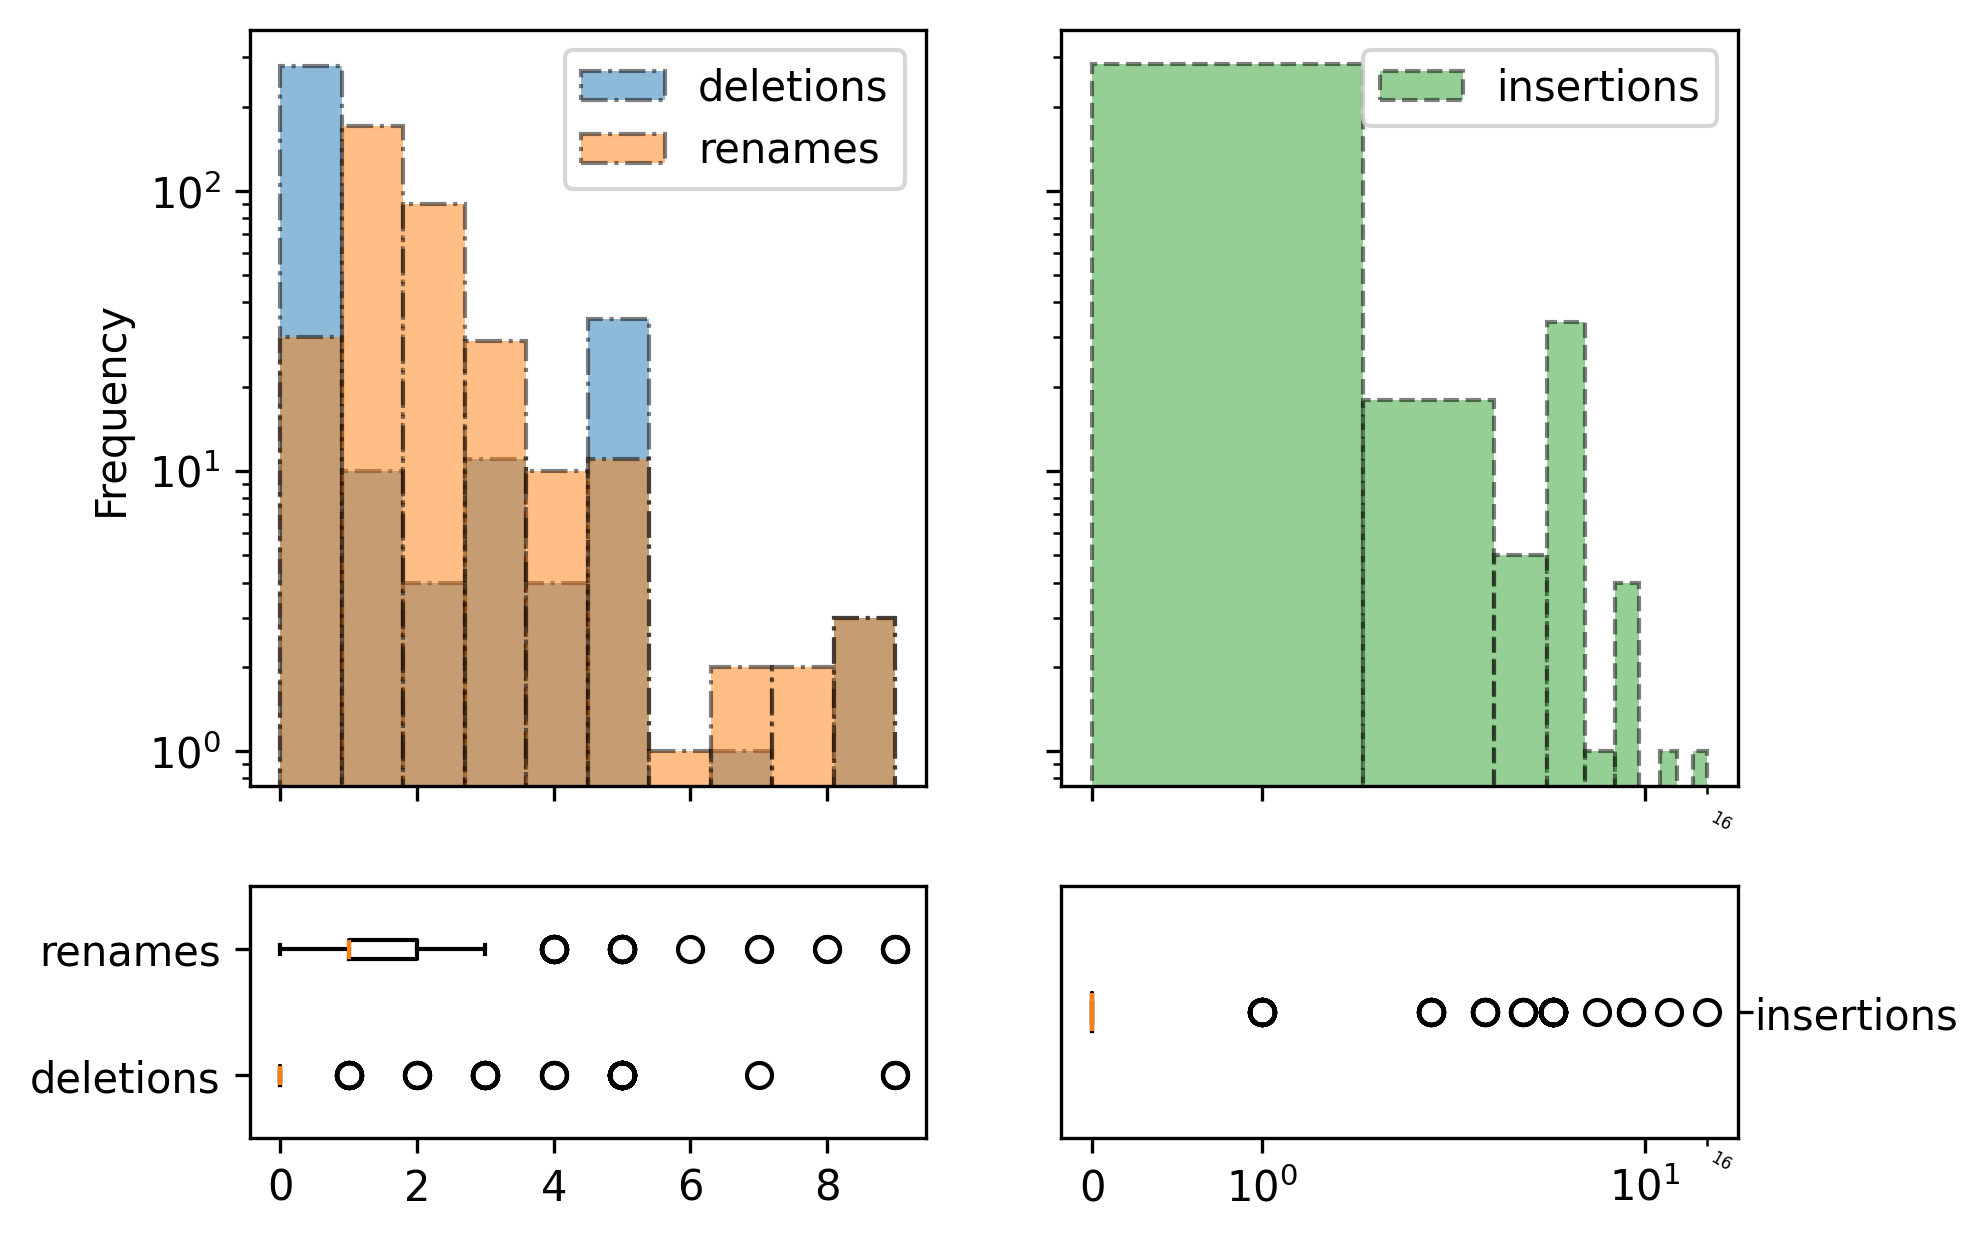

In [173]:
fig, ((ax1, ax2), (bax1, bax2)) = plt.subplots(2,2, height_ratios=((3,1)), dpi=300)
ax1.sharey(ax2)
ax1.sharex(bax1)
ax2.sharex(bax2)
ax2.set_xscale("symlog")
valid_xml_exp_dwc_ground_truth_edit_mapping_counts[["deletions", "renames"]].plot.hist(log=True, alpha=0.5, ls="-.", edgecolor="black", ax=ax1)
bax1.boxplot(
    [
        valid_xml_exp_dwc_ground_truth_edit_mapping_counts["deletions"],
        valid_xml_exp_dwc_ground_truth_edit_mapping_counts["renames"],
    ],
    tick_labels=["deletions", "renames"],
    vert=False
)
bax1.tick_params(axis="y", right=False, labelright=False, left=True, labelleft=True)

valid_xml_exp_dwc_ground_truth_edit_mapping_counts[["insertions"]].plot.hist(log=True, alpha=0.5, ls="--", edgecolor="black", ax=ax2, color="tab:green")
bax2.boxplot(
    [
        valid_xml_exp_dwc_ground_truth_edit_mapping_counts["insertions"],
    ],
    tick_labels=["insertions"],
    vert=False
)
bax2.tick_params(axis="y", right=True, labelright=True, left=False, labelleft=False, pad=0.5)
bax2.tick_params(axis="x", which="minor", pad=0.5)
bax2.set_xticks(
    [valid_xml_exp_dwc_ground_truth_edit_mapping_counts["insertions"].min(), math.floor(valid_xml_exp_dwc_ground_truth_edit_mapping_counts["insertions"].median()), valid_xml_exp_dwc_ground_truth_edit_mapping_counts["insertions"].max()],
    minor=True
)
ax2.set_xticklabels(
    [], 
    minor=True, 
    fontsize=4,
    horizontalalignment="left",
    rotation=330,
)
bax2.set_xticklabels(
    [valid_xml_exp_dwc_ground_truth_edit_mapping_counts["insertions"].min(), math.floor(valid_xml_exp_dwc_ground_truth_edit_mapping_counts["insertions"].median()), valid_xml_exp_dwc_ground_truth_edit_mapping_counts["insertions"].max()], 
    minor=True, 
    fontsize=4,
    horizontalalignment="left",
    rotation=330,
)
plt.show()

### Ground Truth Common Sub-Trees
- Common embedded subtrees
- Common identical subtrees

### Ground-Truth Semantic Similarity

- ????